In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
from bioframe import overlap
#import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
import gzip
from numpy import diff
from scipy import signal
import scipy.ndimage
from matplotlib.ticker import EngFormatter
from scipy.stats import pearsonr
import polars as pl

In [2]:
# === File paths ===
file_path_proM = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/proM_fastq/droplethic_merged_dedup_sorted.pairs"
file_path_G1   = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/Asynch_fastq/droplethic_merged_dedup_sorted.pairs"

# === Helper function to load a .pairs file lazily ===
def load_pairs_lazy(path):
    df = (
        pl.scan_csv(
            path,
            separator="\t",
            comment_char="#",
            has_header=False,
            quote_char='"',
            null_values=["null"]
        )
        .rename({
            "column_1": "readID", "column_2": "chrom1", "column_3": "pos1",
            "column_4": "chrom2", "column_5": "pos2", "column_6": "strand1",
            "column_7": "strand2", "column_8": "pair_type", "column_9": "mapq1",
            "column_10": "mapq2", "column_11": "BX1", "column_12": "BX2"
        })
    )
    return df

# === Load both datasets ===
df_proM = load_pairs_lazy(file_path_proM)
df_G1   = load_pairs_lazy(file_path_G1)

# === Function to compute cis/trans counts ===
def compute_cis_trans(df):
    cis_trans = (
        df.with_columns((pl.col("chrom1") == pl.col("chrom2")).alias("is_cis"))
          .groupby("is_cis")
          .count()
          .collect(streaming=True)
    )
    cis_contacts = cis_trans.filter(pl.col("is_cis") == True)["count"][0]
    trans_contacts = cis_trans.filter(pl.col("is_cis") == False)["count"][0]
    cis_ratio = cis_contacts / (cis_contacts + trans_contacts)
    return cis_contacts, trans_contacts, cis_ratio

# === Compute for both ===
cis_proM, trans_proM, ratio_proM = compute_cis_trans(df_proM)
cis_G1, trans_G1, ratio_G1       = compute_cis_trans(df_G1)

# === Print summary ===
print("=== proM stage ===")
print(f"Cis contacts: {cis_proM:,}")
print(f"Trans contacts: {trans_proM:,}")
print(f"Cis ratio: {ratio_proM:.4f}\n")

print("=== G1 stage ===")
print(f"Cis contacts: {cis_G1:,}")
print(f"Trans contacts: {trans_G1:,}")
print(f"Cis ratio: {ratio_G1:.4f}")

/tmp/ipykernel_867937/1319300684.py:8: DeprecationWarning: `the argument comment_char` for `scan_csv` is deprecated. It has been renamed to `comment_prefix`.
  pl.scan_csv(
/tmp/ipykernel_867937/1319300684.py:33: DeprecationWarning: `groupby` is deprecated. It has been renamed to `group_by`.
  .groupby("is_cis")
/tmp/ipykernel_867937/1319300684.py:34: DeprecationWarning: `count` is deprecated. It has been renamed to `len`.
  .count()


=== proM stage ===
Cis contacts: 415,471,034
Trans contacts: 27,008,524
Cis ratio: 0.9390

=== G1 stage ===
Cis contacts: 364,283,590
Trans contacts: 26,405,891
Cis ratio: 0.9324


In [6]:
# --- Filter, save, and compute cis/trans ratios ---
def filter_and_summarize(
    df_lazy: pl.LazyFrame,
    out_path: str,
    min_sep_bp: int = 400,      # 0.4 kb threshold
    keep_pair_type: str = "UU",
    include_header: bool = False,  # .pairs usually has no header
):
    """
    1) Ensure dtypes (pos1/pos2 as Int64; BX1/BX2 as Utf8 if present)
    2) Keep pair_type == keep_pair_type
    3) Drop near-diagonal cis contacts with |pos1-pos2| < min_sep_bp
    4) Save filtered pairs to out_path (streaming)
    5) Compute cis/trans counts and cis ratio (streaming)
    """
    # Build conditional casts depending on available columns in the LazyFrame schema
    sch = df_lazy.schema
    casts = [
        pl.col("pos1").cast(pl.Int64, strict=False),
        pl.col("pos2").cast(pl.Int64, strict=False),
    ]
    if "BX1" in sch:
        casts.append(pl.col("BX1").cast(pl.Utf8, strict=False))
    if "BX2" in sch:
        casts.append(pl.col("BX2").cast(pl.Utf8, strict=False))

    # Normalize dtypes, filter by pair_type, drop near-diagonal cis
    df_filt = (
        df_lazy
        .with_columns(casts)
        .filter(pl.col("pair_type") == keep_pair_type)
        .filter(
            ~(
                (pl.col("chrom1") == pl.col("chrom2")) &
                ((pl.col("pos1") - pl.col("pos2")).abs() < min_sep_bp)
            )
        )
    )

    # Write filtered pairs (streaming)
    df_filt.sink_csv(
        out_path,
        separator="\t",
        include_header=include_header,
    )

    # Compute cis/trans in streaming mode
    cis_trans = (
        df_filt
        .with_columns((pl.col("chrom1") == pl.col("chrom2")).alias("is_cis"))
        .groupby("is_cis")
        .count()
        .collect(streaming=True)
    )

    # Safely extract counts
    def _get_count(is_cis: bool) -> int:
        sub = cis_trans.filter(pl.col("is_cis") == is_cis)
        return int(sub["count"][0]) if sub.height else 0

    cis_contacts   = _get_count(True)
    trans_contacts = _get_count(False)
    total = cis_contacts + trans_contacts
    cis_ratio = (cis_contacts / total) if total > 0 else float("nan")

    print(f"Filtered file saved to: {out_path}")
    print(f"Cis contacts:   {cis_contacts:,}")
    print(f"Trans contacts: {trans_contacts:,}")
    print(f"Cis ratio:      {cis_ratio:.4f}")

    return df_filt, cis_contacts, trans_contacts, cis_ratio

In [18]:
# Force correct dtypes for .pairs (fixes BX parse issues)
PAIRS_SCHEMA = {
    "column_1":  pl.Utf8,   # readID
    "column_2":  pl.Utf8,   # chrom1
    "column_3":  pl.Int64,  # pos1
    "column_4":  pl.Utf8,   # chrom2
    "column_5":  pl.Int64,  # pos2
    "column_6":  pl.Utf8,   # strand1
    "column_7":  pl.Utf8,   # strand2
    "column_8":  pl.Utf8,   # pair_type
    "column_9":  pl.Int64,  # mapq1
    "column_10": pl.Int64,  # mapq2
    "column_11": pl.Utf8,   # BX1
    "column_12": pl.Utf8,   # BX2
}

def load_pairs_lazy(path: str) -> pl.LazyFrame:
    return (
        pl.scan_csv(
            path,
            separator="\t",
            comment_char="#",
            has_header=False,
            quote_char='"',
            null_values=["null"],
            dtypes=PAIRS_SCHEMA,      # <- critical
            infer_schema_length=0,    # trust schema, don’t re-infer
        )
        .rename({
            "column_1": "readID", "column_2": "chrom1", "column_3": "pos1",
            "column_4": "chrom2", "column_5": "pos2", "column_6": "strand1",
            "column_7": "strand2", "column_8": "pair_type", "column_9": "mapq1",
            "column_10": "mapq2", "column_11": "BX1", "column_12": "BX2"
        })
    )

# Recreate both LazyFrames with the fixed schema
df_proM = load_pairs_lazy("/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/proM_fastq/droplethic_merged_dedup_sorted.pairs")
df_G1   = load_pairs_lazy("/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/Asynch_fastq/droplethic_merged_dedup_sorted.pairs")

/tmp/ipykernel_3571980/1398370501.py:19: DeprecationWarning:

`the argument comment_char` for `scan_csv` is deprecated. It has been renamed to `comment_prefix`.



In [10]:
df_proM_filt, cis_p, trans_p, ratio_p = filter_and_summarize(df_proM, "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/proM_fastq/proM_filtered.pairs")
df_G1_filt,  cis_g, trans_g, ratio_g  = filter_and_summarize(df_G1,  "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/Asynch_fastq/G1_filtered.pairs")

/tmp/ipykernel_1798591/2847418542.py:52: DeprecationWarning: `groupby` is deprecated. It has been renamed to `group_by`.
  .groupby("is_cis")
/tmp/ipykernel_1798591/2847418542.py:53: DeprecationWarning: `count` is deprecated. It has been renamed to `len`.
  .count()


Filtered file saved to: /home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/proM_fastq/proM_filtered.pairs
Cis contacts:   10,254,518
Trans contacts: 6,013,698
Cis ratio:      0.6303
Filtered file saved to: /home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/Asynch_fastq/G1_filtered.pairs
Cis contacts:   10,970,180
Trans contacts: 6,882,794
Cis ratio:      0.6145


# plot the pseudobulk density map

In [11]:
# === 1. Fetch hg38 chromosome sizes, centromeres, and arms ===
hg38_chromsizes = bf.fetch_chromsizes("hg38")
hg38_cens = bf.fetch_centromeres("hg38")
hg38_arms = bf.make_chromarms(hg38_chromsizes, hg38_cens)
hg38_arms["arm"] = hg38_arms["name"].str.split("_").str[1]
canonical_chroms = list(set(hg38_arms["chrom"]))

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amin at 0x147cacaabf60> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amax at 0x147cacaabd80> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()


/tmp/ipykernel_1798591/1224757035.py:20: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
  cis_contacts = int(df_cis.select(pl.count()).collect(streaming=True)[0, 0])


proM cis contacts (>|1000 bp): 7,664,639
G1   cis contacts (>|1000 bp): 8,108,310
Sampled proM: 20,000 rows; G1: 20,000 rows


/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


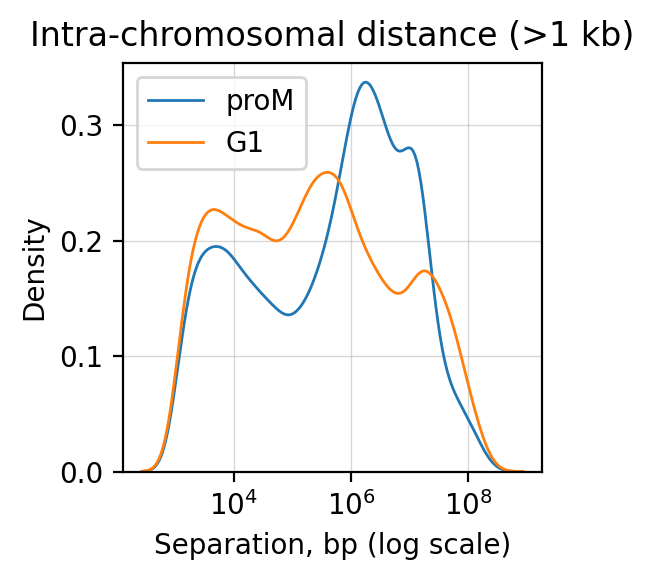

In [18]:
# --- Helper: build cis pipeline, count, sample ~target rows ---
def cis_sample(df_lazy: pl.LazyFrame,
               canonical_chroms,
               min_sep_bp: int = 1000,
               target: int = 1_000_000,
               batch_size: int = 5_000_000,
               per_batch_n: int = 10_000):
    """
    Returns: (cis_contacts:int, df_sample: pl.DataFrame with Abs_Dist)
    """
    df_cis = (
        df_lazy
        .filter(pl.col("chrom1") == pl.col("chrom2"))
        .filter(pl.col("chrom1").is_in(canonical_chroms))
        .with_columns((pl.col("pos1") - pl.col("pos2")).abs().alias("Abs_Dist"))
        .filter(pl.col("Abs_Dist") > min_sep_bp)
    )

    # Count (streaming)
    cis_contacts = int(df_cis.select(pl.count()).collect(streaming=True)[0, 0])

    # Sample in streaming batches
    samples = []
    for batch in df_cis.collect(streaming=True).iter_slices(batch_size):
        if batch.height == 0:
            continue
        take_n = min(per_batch_n, batch.height)
        samples.append(batch.sample(n=take_n))
        if sum(s.height for s in samples) >= target:
            break

    df_sample = pl.concat(samples) if samples else pl.DataFrame({"Abs_Dist": []})
    return cis_contacts, df_sample

# --- Canonical chromosomes (edit if needed) ---
canonical_chroms = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

# === Run for both datasets ===
cis_prom, prom_sample = cis_sample(df_proM, canonical_chroms,
                                   min_sep_bp=1000, target=1_000_000,
                                   batch_size=5_000_000, per_batch_n=10_000)
cis_g1,   g1_sample   = cis_sample(df_G1,   canonical_chroms,
                                   min_sep_bp=1000, target=1_000_000,
                                   batch_size=5_000_000, per_batch_n=10_000)

print(f"proM cis contacts (>|{1000} bp): {cis_prom:,}")
print(f"G1   cis contacts (>|{1000} bp): {cis_g1:,}")
print(f"Sampled proM: {prom_sample.height:,} rows; G1: {g1_sample.height:,} rows")

# === Plot: overlaid KDE on one axis (log-scaled x) ===
plt.figure(figsize=(3, 3), dpi=200)
sns.kdeplot(data=prom_sample.to_pandas(), x="Abs_Dist", lw=1, log_scale=True, label="proM")
sns.kdeplot(data=g1_sample.to_pandas(),   x="Abs_Dist", lw=1, log_scale=True, label="G1")
plt.xlabel("Separation, bp (log scale)")
plt.ylabel("Density")
plt.title("Intra-chromosomal distance (>1 kb)")
plt.grid(lw=0.5, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


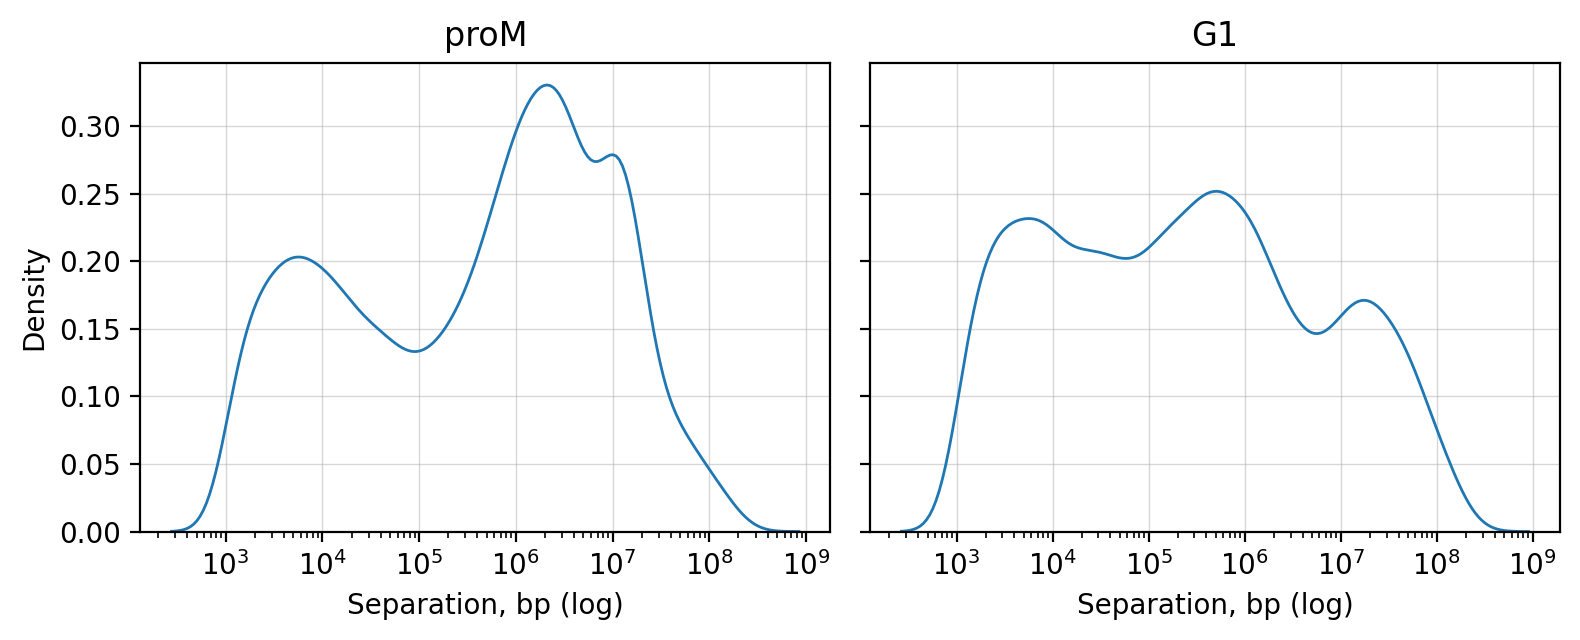

In [17]:
# === (Optional) side-by-side subplots ===
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), dpi=200, sharey=True)
sns.kdeplot(data=prom_sample.to_pandas(), x="Abs_Dist", lw=1, log_scale=True, ax=axes[0])
axes[0].set_title("proM"); axes[0].set_xlabel("Separation, bp (log)"); axes[0].set_ylabel("Density"); axes[0].grid(lw=0.5, alpha=0.5)
sns.kdeplot(data=g1_sample.to_pandas(), x="Abs_Dist", lw=1, log_scale=True, ax=axes[1])
axes[1].set_title("G1"); axes[1].set_xlabel("Separation, bp (log)"); axes[1].grid(lw=0.5, alpha=0.5)
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot/DropletH1_benchmark_proM_G1_densityplot.pdf",dpi=200)
plt.show()

# check the single-cell statistics

In [14]:
# --- Count unique BX1 barcodes before filtering ---
n_bx1_proM = df_proM.select(pl.col("BX1").n_unique()).collect().item()
n_bx1_G1   = df_G1.select(pl.col("BX1").n_unique()).collect().item()

print("=== Unique BX1 barcodes before filtering ===")
print(f"proM: {n_bx1_proM:,}")
print(f"G1:   {n_bx1_G1:,}")

=== Unique BX1 barcodes before filtering ===
proM: 7,911,378
G1:   4,437,680


In [15]:
def bx1_over_threshold(df_lazy: pl.LazyFrame, threshold: int = 5_000):
    # Count per BX1
    counts = df_lazy.groupby("BX1").agg(pl.len().alias("cnt"))

    # Join counts back
    df_with_counts = df_lazy.join(counts, on="BX1", how="left")

    # Filter BX1 with count > threshold
    filtered = df_with_counts.filter(pl.col("cnt") > threshold)

    # Number of unique BX1 passing the threshold
    n_bx1 = filtered.select(pl.col("BX1").n_unique()).collect(streaming=True).item()

    # (Optional) also return a small table of top BX1s by count
    top_counts = (
        counts.sort("cnt", descending=True)
              .limit(10)
              .collect(streaming=True)
    )
    return n_bx1, top_counts

# Run for both datasets
threshold = 5_000   # change to 20_000 if you meant “more than 20,000 times”
n_bx1_prom, top_prom = bx1_over_threshold(df_proM, threshold=threshold)
n_bx1_g1,   top_g1   = bx1_over_threshold(df_G1,   threshold=threshold)

print(f"=== BX1 with >{threshold:,} counts ===")
print(f"proM: {n_bx1_prom:,}")
print(f"G1:   {n_bx1_g1:,}")

print("\nTop 10 BX1 by count (proM):")
print(top_prom)

print("\nTop 10 BX1 by count (G1):")
print(top_g1)

/tmp/ipykernel_1798591/3151404555.py:3: DeprecationWarning: `groupby` is deprecated. It has been renamed to `group_by`.
  counts = df_lazy.groupby("BX1").agg(pl.len().alias("cnt"))


=== BX1 with >5,000 counts ===
proM: 10,985
G1:   7,240

Top 10 BX1 by count (proM):
shape: (10, 2)
┌──────────────────┬─────────┐
│ BX1              ┆ cnt     │
│ ---              ┆ ---     │
│ str              ┆ u32     │
╞══════════════════╪═════════╡
│ null             ┆ 9822167 │
│ GGGGGGGGGGGGGGGG ┆ 1944179 │
│ CGTGGGTACATCCTCC ┆ 249944  │
│ CGTGAATACTGCTTGA ┆ 246759  │
│ CGTTGCTTGGAATCTC ┆ 238934  │
│ TCGCCTCCTTGCGCCA ┆ 228084  │
│ CCAGCACGAGTTAGAA ┆ 226002  │
│ CTCTCTGGACGATGGA ┆ 223413  │
│ GTTGAGTTGCAGGGAT ┆ 211009  │
│ CGTTACCTGCTCGAGC ┆ 204318  │
└──────────────────┴─────────┘

Top 10 BX1 by count (G1):
shape: (10, 2)
┌──────────────────┬───────────┐
│ BX1              ┆ cnt       │
│ ---              ┆ ---       │
│ str              ┆ u32       │
╞══════════════════╪═══════════╡
│ 0                ┆ 115972055 │
│ null             ┆ 9329851   │
│ GGGGGGGGGGGGGGGG ┆ 1177952   │
│ CATTCAACTCCGGACT ┆ 219428    │
│ TAGCAGACTCATCCTC ┆ 206180    │
│ GTTTCAGGACGACTAT ┆ 191079    │

In [ ]:
#allow 1 mismatching

In [23]:
def collapse_barcodes(df_lazy: pl.LazyFrame, stage_name: str, min_count: int = 100, top_n: int = 10_000):
    """
    Collapse BX1 barcodes allowing ≤1 mismatch.
    Removes null, empty, '0', 'null', and 'GGGGGGGGGGGGGGGG' barcodes first.
    """
    # --- Step 1: Count contacts per BX1 (after cleaning) ---
    bad_barcodes = {"", "0", "null", "GGGGGGGGGGGGGGGG"}
    cnt_df = (
        df_lazy
        .filter(
            (pl.col("BX1").is_not_null()) &
            (~pl.col("BX1").is_in(list(bad_barcodes)))
        )
        .group_by("BX1")
        .agg(pl.len().alias("count"))
        .sort("count", descending=True)
    )

    # Collect into pandas
    cnt = cnt_df.collect(streaming=True).to_pandas().set_index("BX1")["count"]

    # --- Step 2: Select seed barcodes ---
    seed_mask  = cnt > min_count
    seeds      = cnt[seed_mask].head(top_n)
    seed_index = set(seeds.index)
    consolidated = seeds.to_dict()

    # --- Step 3: Build one-mismatch lookup table ---
    bases = ["A", "C", "G", "T"]
    variant_to_seed = {}

    for bc in seed_index:
        if not isinstance(bc, str):
            continue
        variant_to_seed[bc] = bc  # exact match
        for i, b in enumerate(bc):
            for alt in bases:
                if alt != b:
                    v = bc[:i] + alt + bc[i+1:]
                    # Keep the higher-count seed if collision
                    if v not in variant_to_seed or seeds[bc] > seeds.get(variant_to_seed[v], 0):
                        variant_to_seed[v] = bc

    # --- Step 4: Fold non-seed barcodes into seeds if ≤1 mismatch ---
    for bc, n in cnt.items():
        if bc in seed_index or not isinstance(bc, str):
            continue
        target = variant_to_seed.get(bc)
        if target:
            consolidated[target] += n

    # --- Step 5: Final collapsed counts ---
    final_cnt = (
        pl.DataFrame({
            "BX1": list(consolidated.keys()),
            "count": list(consolidated.values())
        })
        .sort("count", descending=True)
    )

    print(f"\n=== {stage_name} ===")
    print(f"Seeds (count>{min_count}): {len(seeds):,}")
    print(f"Collapsed to unique barcodes: {final_cnt.height:,}")
    print(final_cnt.head())

    return final_cnt

In [24]:
collapsed_proM = collapse_barcodes(df_proM, "proM", min_count=100, top_n=10_000)
collapsed_G1   = collapse_barcodes(df_G1,   "G1",   min_count=100, top_n=10_000)

# Count BX1s with >10,000 contacts
n_above_10000_proM = collapsed_proM.filter(pl.col("count") > 10_000).height
n_above_10000_G1   = collapsed_G1.filter(pl.col("count") > 10_000).height

print("\n=== BX1 barcodes with >10,000 contacts ===")
print(f"proM: {n_above_10000_proM:,}")
print(f"G1:   {n_above_10000_G1:,}")


=== proM ===
Seeds (count>100): 10,000
Collapsed to unique barcodes: 10,000
shape: (5, 2)
┌──────────────────┬────────┐
│ BX1              ┆ count  │
│ ---              ┆ ---    │
│ str              ┆ i64    │
╞══════════════════╪════════╡
│ CGTGGGTACATCCTCC ┆ 253368 │
│ CGTGAATACTGCTTGA ┆ 249220 │
│ CGTTGCTTGGAATCTC ┆ 243684 │
│ TCGCCTCCTTGCGCCA ┆ 236885 │
│ CCAGCACGAGTTAGAA ┆ 228887 │
└──────────────────┴────────┘

=== G1 ===
Seeds (count>100): 10,000
Collapsed to unique barcodes: 10,000
shape: (5, 2)
┌──────────────────┬────────┐
│ BX1              ┆ count  │
│ ---              ┆ ---    │
│ str              ┆ i64    │
╞══════════════════╪════════╡
│ CATTCAACTCCGGACT ┆ 225604 │
│ TAGCAGACTCATCCTC ┆ 209441 │
│ GTTTCAGGACGACTAT ┆ 192820 │
│ CTGCACGGACCCGAGT ┆ 178138 │
│ TGCCGTGGATCGCTAA ┆ 175838 │
└──────────────────┴────────┘

=== BX1 barcodes with >10,000 contacts ===
proM: 6,437
G1:   4,234


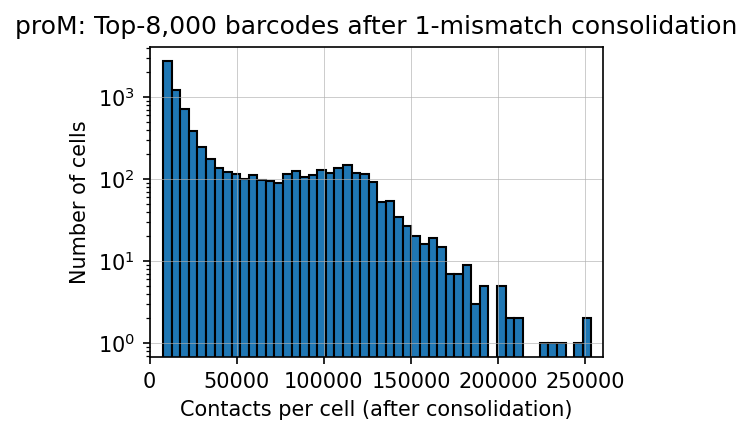

=== proM — Top 8,000 summary ===
Mean:   38796.5
Median: 17578.5
Min–Max: 7,805 – 253,368



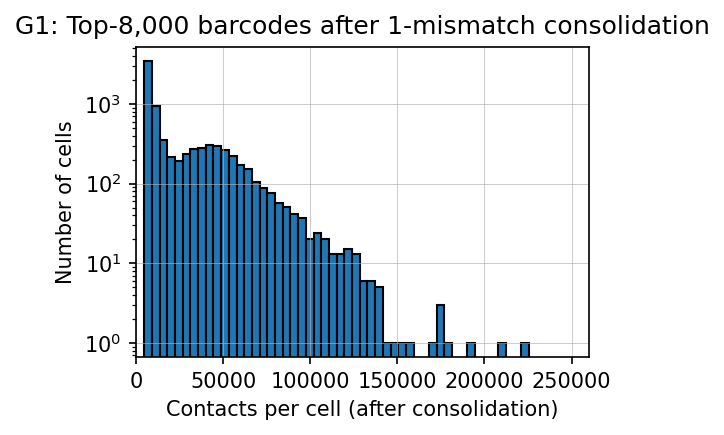

=== G1 — Top 8,000 summary ===
Mean:   25044.3
Median: 10984.5
Min–Max: 4,784 – 225,604



In [26]:
def plot_top_consolidated(final_cnt, stage_name: str, top_n: int = 8000, xlim_max: int | None = None):
    # Step 1. Take top-N barcodes
    topN = final_cnt.head(top_n)

    # Step 2. Extract counts as NumPy array
    counts = topN["count"].to_numpy()

    # Step 3. Plot histogram
    plt.figure(figsize=(4, 3), dpi=150)
    plt.hist(counts, bins=50, edgecolor="black")
    plt.xlabel("Contacts per cell (after consolidation)")
    plt.ylabel("Number of cells")
    plt.yscale("log")
    plt.title(f"{stage_name}: Top-{top_n:,} barcodes after 1-mismatch consolidation")
    if xlim_max is not None:
        plt.xlim(0, xlim_max)
    plt.grid(True, lw=0.3)
    plt.tight_layout()
    plt.show()

    print(f"=== {stage_name} — Top {top_n:,} summary ===")
    print(f"Mean:   {np.mean(counts):.1f}")
    print(f"Median: {np.median(counts):.1f}")
    print(f"Min–Max: {np.min(counts):,} – {np.max(counts):,}\n")
    return topN

# Run for both stages (uses your consolidated outputs: collapsed_proM, collapsed_G1)
top8k_proM = plot_top_consolidated(collapsed_proM, "proM", top_n=8000, xlim_max=260000)       # set xlim_max=300_000 if you like
top8k_G1   = plot_top_consolidated(collapsed_G1,   "G1",   top_n=8000, xlim_max=260000)

# plot single cell heatmap and pairwise distance density plot

In [20]:
#get top 10 or 5 barcodes
def get_top10_barcodes(df_lazy: pl.LazyFrame, stage_name: str):
    """
    Remove invalid BX1 barcodes and return the top 10 most covered ones.
    """
    bad_barcodes = {"", "0", "null", "GGGGGGGGGGGGGGGG"}

    top10_barcodes = (
        df_lazy
        .filter(
            (pl.col("BX1").is_not_null()) &
            (~pl.col("BX1").is_in(list(bad_barcodes)))
        )
        .group_by("BX1")
        .agg(pl.len().alias("count"))
        .sort("count", descending=True)
        .head(5)
        .collect(streaming=True)["BX1"]
        .to_list()
    )

    print(f"=== {stage_name}: Top 10 BX1 barcodes (after filtering) ===")
    for i, bc in enumerate(top10_barcodes, 1):
        print(f"{i:2d}. {bc}")
    return top10_barcodes

In [21]:
# Run for both datasets
top10_proM = get_top10_barcodes(df_proM, "proM")
top10_G1   = get_top10_barcodes(df_G1,   "G1")

=== proM: Top 10 BX1 barcodes (after filtering) ===
 1. CGTGGGTACATCCTCC
 2. CGTGAATACTGCTTGA
 3. CGTTGCTTGGAATCTC
 4. TCGCCTCCTTGCGCCA
 5. CCAGCACGAGTTAGAA
=== G1: Top 10 BX1 barcodes (after filtering) ===
 1. CATTCAACTCCGGACT
 2. TAGCAGACTCATCCTC
 3. GTTTCAGGACGACTAT
 4. CTGCACGGACCCGAGT
 5. TGCCGTGGATCGCTAA


# chr1 plot

In [25]:
def pairs_to_bedlike(pairs_df):
    bed1 = pd.DataFrame({
        "qname" : pairs_df["readID"],
        "qstart": pairs_df["pos1"] - 1,
        "qend"  : pairs_df["pos1"],
        "strand": pairs_df["strand1"],
        "chrom" : pairs_df["chrom1"],
        "start" : pairs_df["pos1"] - 1,
        "end"   : pairs_df["pos1"],
    })
    bed2 = pd.DataFrame({
        "qname" : pairs_df["readID"],
        "qstart": pairs_df["pos2"] - 1,
        "qend"  : pairs_df["pos2"],
        "strand": pairs_df["strand2"],
        "chrom" : pairs_df["chrom2"],
        "start" : pairs_df["pos2"] - 1,
        "end"   : pairs_df["pos2"],
    })
    return pd.concat([bed1, bed2], ignore_index=True)

In [31]:
import bioframe, cooler
from matplotlib import colors
from scipy.sparse import coo_matrix

def get_pixels(df, binsize, cond, chrom="chr1"):
    # 1) Build bins ONLY for the requested chromosome
    chromsizes = bioframe.fetch_chromsizes("hg38")  # pandas Series
    chromsizes = chromsizes.loc[[chrom]]            # keep just chr1 (or any chrom)
    bins = cooler.binnify(chromsizes, binsize)      # 1Mb bins if binsize=1_000_000
    bins = bins.reset_index().rename(columns={"index":"name"})

    # 2) Keep only rows on the selected chromosome
    df = df[df["chrom"] == chrom].copy()
    if df.empty:
        print(f"{cond} | no {chrom} contacts")
        N = len(bins)
        return np.zeros((N, N), dtype=int)

    # 3) Assign bins (view) and build “almost_pixels”
    binned_df = bioframe.assign_view(
        df.sort_values(["qname","qstart"]),
        bins,
        drop_unassigned=False,
        df_view_col="bin_id",
        view_name_col="name",
        cols=None
    ).dropna(axis=0, how='any')

    _pixels = pd.merge(
        binned_df.iloc[:-1].reset_index(drop=True),
        binned_df.iloc[1:].reset_index(drop=True),
        left_index=True, right_index=True, suffixes=('1','2')
    )[["qname1","qstart1","qend1","strand1","chrom1","start1","end1",
       "qname2","qstart2","qend2","strand2","chrom2","start2","end2",
       "bin_id1","bin_id2"]]

    _from_same_read = (_pixels["qname1"] == _pixels["qname2"])
    _are_consequtive = (_pixels["qend1"] == _pixels["qstart2"]).abs() < 1_000_000
    almost_pixels = _pixels[_from_same_read & _are_consequtive].drop("qname2", axis=1).reset_index(drop=True)
    print(cond, f"| direct interactions (gap<1Mb):", len(almost_pixels))

    # 4) Symmetrize & count
    flip_mask = (almost_pixels["bin_id1"] > almost_pixels["bin_id2"]).values
    almost_pixels.loc[flip_mask, ["bin_id1","bin_id2"]] = (
        almost_pixels.loc[flip_mask, ["bin_id2","bin_id1"]].values
    )
    almost_pixels = (
        almost_pixels.groupby(["bin_id1","bin_id2"])
        .size().reset_index(name="count")
        .rename(columns={"bin_id1":"bin1_id","bin_id2":"bin2_id"})
    )

    # Optional QC (still works with chr1-only bins)
    chrom_pixels = cooler.annotate(almost_pixels, bins[["chrom"]])
    trans = chrom_pixels["count"][chrom_pixels["chrom1"] != chrom_pixels["chrom2"]].sum()
    cis   = chrom_pixels["count"][chrom_pixels["chrom1"] == chrom_pixels["chrom2"]].sum()
    diag  = chrom_pixels["count"][chrom_pixels["bin1_id"] == chrom_pixels["bin2_id"]].sum()
    total = chrom_pixels["count"].sum()
    print("count trans/cis/diag/total :", trans, cis, diag, total)

    # 5) Make matrix for chr1 at 1Mb bins
    N = len(bins)
    mat = coo_matrix(
        (almost_pixels["count"], (almost_pixels["bin1_id"], almost_pixels["bin2_id"])),
        shape=(N, N)
    ).toarray()
    mat = mat + mat.T
    print(f"generated symmetric matrix {N}×{N} for {chrom} @ {binsize//1_000_000} Mb")
    return mat

In [32]:
BIN_SIZE = 2_000_000  # 2 Mb

def build_mats_for_stage(df_lazy: pl.LazyFrame, barcode_list, stage_name: str,
                         bin_size: int = BIN_SIZE, min_sep_bp: int = 1000,
                         target_chrom: str = "chr1"):
    mats = {}
    barcode_list = list(dict.fromkeys(barcode_list))
    for bc in barcode_list:
        cell_pl = df_lazy.filter(pl.col("BX1") == bc)
        cell_pl = cell_pl.filter(
            ~(
                (pl.col("chrom1") == pl.col("chrom2")) &
                ((pl.col("pos1") - pl.col("pos2")).abs() < min_sep_bp)
            )
        )
        cell_df = (
            cell_pl
            .select(["readID","chrom1","pos1","strand1","chrom2","pos2","strand2","BX1"])
            .with_columns([
                pl.col("pos1").cast(pl.Int64, strict=False),
                pl.col("pos2").cast(pl.Int64, strict=False),
            ])
            .collect(streaming=True)
            .to_pandas()
        )
        if cell_df.empty:
            print(f"[{stage_name}] {bc}: no contacts after filtering; skipping.")
            continue

        bed_df = pairs_to_bedlike(cell_df)

        # keep only chr1 rows before feeding to get_pixels
        bed_df = bed_df[bed_df["chrom"] == target_chrom].copy()
        if bed_df.empty:
            print(f"[{stage_name}] {bc}: no {target_chrom} contacts; skipping.")
            continue

        mat = get_pixels(bed_df, binsize=bin_size, cond=f"{stage_name}:{bc}", chrom=target_chrom)
        mats[bc] = mat
        print(f"[{stage_name}] {bc}: matrix built (chr1 @ {bin_size//1_000_000} Mb; shape {mat.shape[0]}×{mat.shape[1]}).")
    return mats

# Build for both stages (chr1 @ 5Mb)
mats_proM_chr1 = build_mats_for_stage(df_proM, top10_proM, "proM", bin_size=BIN_SIZE, target_chrom="chr1")
mats_G1_chr1   = build_mats_for_stage(df_G1,   top10_G1,   "G1",   bin_size=BIN_SIZE, target_chrom="chr1")

proM:CGTGGGTACATCCTCC | direct interactions (gap<1Mb): 717
count trans/cis/diag/total : 0 717 351 717
generated symmetric matrix 125×125 for chr1 @ 2 Mb
[proM] CGTGGGTACATCCTCC: matrix built (chr1 @ 2 Mb; shape 125×125).
proM:CGTGAATACTGCTTGA | direct interactions (gap<1Mb): 572
count trans/cis/diag/total : 0 572 280 572
generated symmetric matrix 125×125 for chr1 @ 2 Mb
[proM] CGTGAATACTGCTTGA: matrix built (chr1 @ 2 Mb; shape 125×125).
proM:CGTTGCTTGGAATCTC | direct interactions (gap<1Mb): 567
count trans/cis/diag/total : 0 567 305 567
generated symmetric matrix 125×125 for chr1 @ 2 Mb
[proM] CGTTGCTTGGAATCTC: matrix built (chr1 @ 2 Mb; shape 125×125).
proM:TCGCCTCCTTGCGCCA | direct interactions (gap<1Mb): 677
count trans/cis/diag/total : 0 677 336 677
generated symmetric matrix 125×125 for chr1 @ 2 Mb
[proM] TCGCCTCCTTGCGCCA: matrix built (chr1 @ 2 Mb; shape 125×125).
proM:CCAGCACGAGTTAGAA | direct interactions (gap<1Mb): 504
count trans/cis/diag/total : 0 504 226 504
generated symm

/tmp/ipykernel_3571980/2194697937.py:71: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



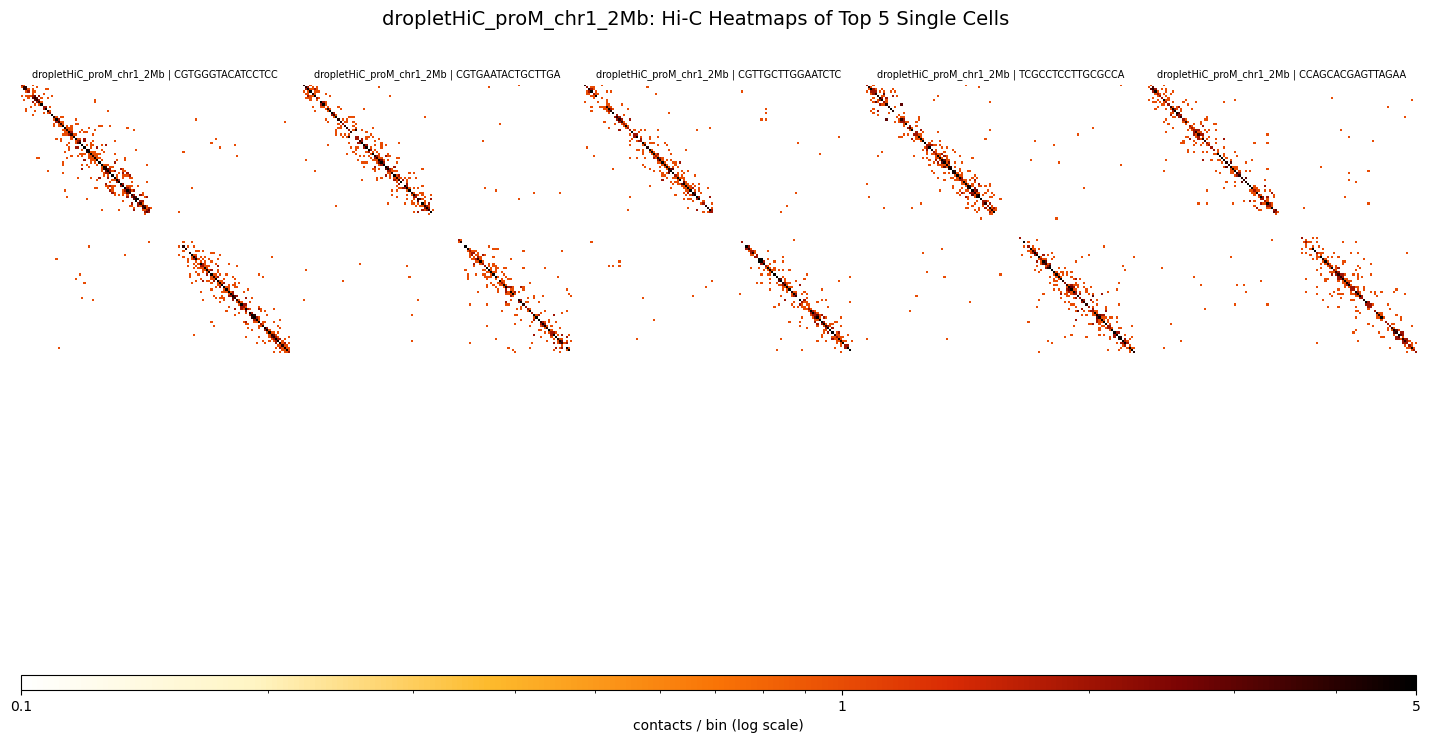

✅ Saved heatmap figure to: /home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiC_proM_chr1_2Mb_chr1_heatmaps.pdf


/tmp/ipykernel_3571980/2194697937.py:71: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



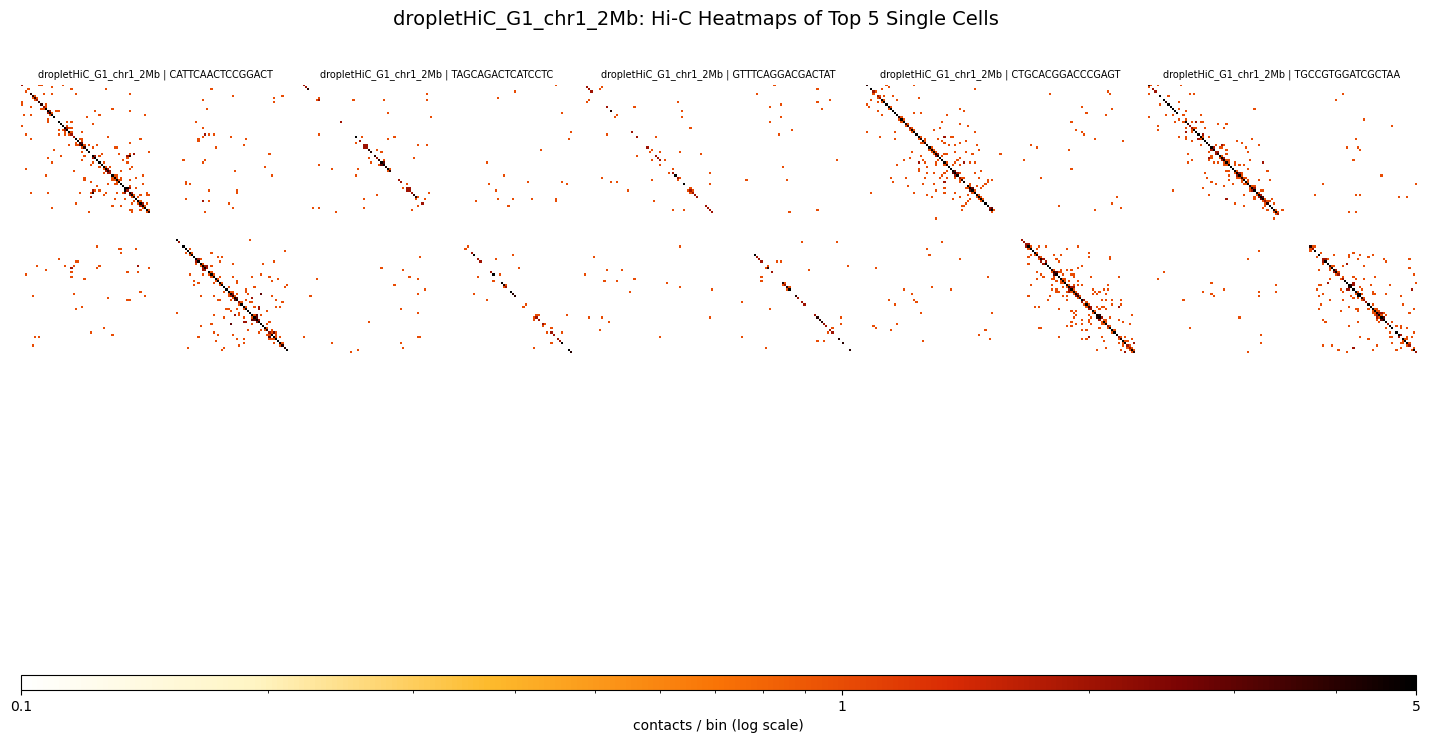

✅ Saved heatmap figure to: /home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiC_G1_chr1_2Mb_chr1_heatmaps.pdf


In [35]:
from matplotlib.colors import LinearSegmentedColormap

def plot_stage_heatmaps(
    mats_dict, stage_name, order=None, N=10,
    n_rows=2, n_cols=5,
    vmin=0.1, vmax=5,   # log scale range
    save_dir="/home/xiangru.huo-umw/scHiC/scripts/plot/",
    fmt="pdf"
):
    """
    Plot Hi-C matrices as a grid of single-cell heatmaps.

    mats_dict : dict {barcode -> 2D numpy array}
    order     : list of barcodes to plot in given order
    N         : number of cells to plot
    """

    # === Define "fall" colormap (white → yellow → orange → red → black) ===
    fall_colors = ["#ffffff", "#fff5c3", "#fdbb2d", "#f97306", "#d92b04", "#7a0403", "#000000"]
    fall_cmap = LinearSegmentedColormap.from_list("fall", fall_colors, N=256)

    os.makedirs(save_dir, exist_ok=True)

    # --- Barcode selection ---
    if order is None:
        barcodes = list(mats_dict.keys())[:N]
    else:
        barcodes = [bc for bc in order if bc in mats_dict][:N]

    if len(barcodes) == 0:
        print(f"[{stage_name}] No matrices to plot.")
        return

    # --- Figure setup ---
    fig = plt.figure(figsize=(18, 8))
    gs  = gridspec.GridSpec(
        n_rows + 1, n_cols,
        height_ratios=[1]*n_rows + [0.05],
        hspace=0.05, wspace=0.05
    )

    last_im = None
    for i, bc in enumerate(barcodes):
        r, c = divmod(i, n_cols)
        ax = fig.add_subplot(gs[r, c])
        mat = np.asarray(mats_dict[bc], dtype=float)

        # mask nonpositive for log scale
        mat[mat <= 0] = np.nan

        im = ax.imshow(
            mat,
            cmap=fall_cmap,  # ← use our custom fall palette
            norm=colors.LogNorm(vmin=vmin, vmax=vmax),
            interpolation="none",
            origin="upper"
        )
        ax.set_title(f"{stage_name} | {bc}", fontsize=7)
        ax.axis("off")
        last_im = im

    # --- Shared colorbar ---
    cbar_ax = fig.add_subplot(gs[-1, :])
    cbar = fig.colorbar(last_im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('contacts / bin (log scale)')
    cbar.set_ticks([0.1, 1, 5])
    cbar.set_ticklabels(['0.1', '1', '5'])

    plt.suptitle(f"{stage_name}: Hi-C Heatmaps of Top {len(barcodes)} Single Cells",
                 fontsize=14, y=0.96)
    plt.tight_layout()

    save_path = os.path.join(save_dir, f"{stage_name}_chr1_heatmaps.{fmt}")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved heatmap figure to: {save_path}")
    
plot_stage_heatmaps(mats_proM_chr1, "dropletHiC_proM_chr1_2Mb", order=top10_proM, N=10)
plot_stage_heatmaps(mats_G1_chr1,   "dropletHiC_G1_chr1_2Mb",   order=top10_G1,   N=10)

# plot Density map (load filter_df)

In [2]:
#read filter_df
# Define the column names for .pairs format
pairs_columns = [
    "readID", "chrom1", "pos1", "chrom2", "pos2",
    "strand1", "strand2", "pair_type", "mapq1", "mapq2",
    "BX1", "BX2"
]

# Define the data types for robust reading
dtypes = {
    "readID": "string",
    "chrom1": "string",
    "pos1": "Int64",
    "chrom2": "string",
    "pos2": "Int64",
    "strand1": "string",
    "strand2": "string",
    "pair_type": "string",
    "mapq1": "Int64",
    "mapq2": "Int64",
    "BX1": "string",
    "BX2": "string",
}

# === Load proM and G1 pairs ===
proM_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/proM_fastq/proM_filtered.pairs"
G1_path   = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-1017/Asynch_fastq/G1_filtered.pairs"

df_proM_filter = pd.read_csv(proM_path,sep="\t",comment="#",names=pairs_columns,dtype=dtypes,na_values=["null", "NA"],engine="python")
df_G1_filter = pd.read_csv(G1_path,sep="\t",comment="#",names=pairs_columns,dtype=dtypes,na_values=["null", "NA"],engine="python")

In [3]:
# --- 1) Get top-50 BX1 (cleaned) + their contact counts ---
def get_top50_barcodes(df_like, stage_name: str):
    """
    Remove invalid BX1 barcodes and return the top 50 most covered ones
    PLUS a dict mapping BX1 -> contact count.
    Works with Polars (LazyFrame/DataFrame) or Pandas DataFrame.
    """
    bad_barcodes = {"", "0", "null", "GGGGGGGGGGGGGGGG", None}

    # --- Polars LazyFrame ---
    if isinstance(df_like, pl.LazyFrame):
        counts_lf = (
            df_like
            .filter(pl.col("BX1").is_not_null() & (~pl.col("BX1").is_in(list(bad_barcodes))))
            .groupby("BX1")
            .agg(pl.len().alias("Num_Contacts"))
            .sort("Num_Contacts", descending=True)
        )
        top_df = counts_lf.head(50).collect(streaming=True)

    # --- Polars eager DataFrame ---
    elif isinstance(df_like, pl.DataFrame):
        df = df_like.filter(pl.col("BX1").is_not_null() & (~pl.col("BX1").is_in(list(bad_barcodes))))
        top_df = (
            df.groupby("BX1")
              .len()
              .rename({"len": "Num_Contacts"})
              .sort("Num_Contacts", descending=True)
              .head(50)
        )

    # --- Pandas DataFrame ---
    elif isinstance(df_like, pd.DataFrame):
        df = df_like[df_like["BX1"].notna() & (~df_like["BX1"].isin(bad_barcodes))]
        top_df = (
            df.groupby("BX1", as_index=False)
              .size()
              .rename(columns={"size": "Num_Contacts"})
              .sort_values("Num_Contacts", ascending=False)
              .head(50)
        )
        # convert to polars-like columns accessor
        top_df = pl.from_pandas(top_df)

    else:
        raise TypeError("df_like must be a Polars LazyFrame/DataFrame or a Pandas DataFrame")

    top_barcodes = top_df["BX1"].to_list()
    contacts_map = dict(zip(top_df["BX1"].to_list(), top_df["Num_Contacts"].to_list()))

    print(f"=== {stage_name}: Top 50 BX1 (after filtering) ===")
    for i, bc in enumerate(top_barcodes, 1):
        print(f"{i:2d}. {bc}  (contacts={contacts_map[bc]:,})")

    return top_barcodes, contacts_map

In [4]:
# Get top 50 barcodes for each stage
top50_proM, contacts_proM = get_top50_barcodes(df_proM_filter, "proM")
top50_G1,   contacts_G1   = get_top50_barcodes(df_G1_filter,   "G1")

=== proM: Top 50 BX1 (after filtering) ===
 1. TCGCCTCCTTGCGCCA  (contacts=23,152)
 2. GCCGACAACTTACGCA  (contacts=18,930)
 3. CATTAGTCTGAACATA  (contacts=18,261)
 4. CGTTACCTGCTCGAGC  (contacts=17,289)
 5. CGTGGGTACATCCTCC  (contacts=16,985)
 6. TCCGAATGATGGCTGC  (contacts=16,747)
 7. TCTTATGACCATCTTT  (contacts=16,659)
 8. CTCTCTGGACGATGGA  (contacts=16,000)
 9. CGTGAATACTGCTTGA  (contacts=15,108)
10. TAACGCATGGCCCAAC  (contacts=14,988)
11. GATATCGTGATACGCT  (contacts=14,440)
12. ACCTATGGACCGCTAG  (contacts=14,070)
13. CAACACCCTAAACTGA  (contacts=14,023)
14. TCGACTCACCCTGAGC  (contacts=13,598)
15. ATCGCAAACGCAGGAT  (contacts=13,546)
16. GTTGAGTTGCAGGGAT  (contacts=13,543)
17. CTAGTGCCTACGCCAC  (contacts=13,527)
18. CGAAATAGACCTGTGG  (contacts=13,377)
19. GAAGTGTCTAATCCGT  (contacts=13,351)
20. CTTAGAGACTGGAACG  (contacts=13,159)
21. CGTTGCTTGGAATCTC  (contacts=13,102)
22. TGATATCCTGTTTACG  (contacts=13,093)
23. GTAATCTCTGAGTGAC  (contacts=13,084)
24. TAGGTAAGACGATTGT  (contacts=12,86

In [5]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, get_cmap
from matplotlib.colors import LogNorm

def plot_distance_kde_with_colorbar_pandas(
    df: pd.DataFrame,
    selected_barcodes,
    contacts_map: dict,
    stage_name: str,
    out_path: str,
    cmap_name="Reds",
    min_contacts=9000,
    min_sep_bp=1000,
    min_points=10,
    figsize=(4.5, 3)
):
    # --- 1. Filter barcodes and data ---
    kept = [bc for bc in selected_barcodes if contacts_map.get(bc, 0) >= min_contacts]
    if not kept:
        print(f"[{stage_name}] No barcodes ≥{min_contacts:,} contacts.")
        return

    sub = df.query("BX1 in @kept and chrom1 == chrom2").copy()
    sub["Abs_Dist"] = (sub["pos1"].astype(int) - sub["pos2"].astype(int)).abs()
    sub = sub.loc[sub["Abs_Dist"] >= min_sep_bp]
    if sub.empty:
        print(f"[{stage_name}] No cis pairs ≥{min_sep_bp:,} bp.")
        return

    # --- 2. Group by barcode & filter ---
    groups = [(bc, g) for bc, g in sub.groupby("BX1") if len(g) >= min_points]
    if not groups:
        print(f"[{stage_name}] No barcode with ≥{min_points} points.")
        return

    # --- 3. Log-scaled color normalization ---
    contacts_vals = np.array([contacts_map.get(bc, 0) for bc, _ in groups], float)
    vmin, vmax = contacts_vals.min(), contacts_vals.max()
    if vmin <= 0: vmin = 1  # avoid log(0)
    norm = LogNorm(vmin=vmin, vmax=vmax)
    cmap = get_cmap(cmap_name)

    # --- 4. Plot ---
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    plt.figure(figsize=figsize, dpi=150)

    for bc, g in groups:
        sns.kdeplot(
            g["Abs_Dist"], lw=1, log_scale=True, common_norm=False,
            color=cmap(norm(contacts_map.get(bc, 1))), alpha=0.9, legend=False
        )

    plt.xlim(1e2, 1e9)
    plt.ylim(0, 0.5)

    # --- 5. Log-scaled colorbar ---
    sm = ScalarMappable(norm=norm, cmap=cmap)
    cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
    cbar.set_label("Contacts per barcode (log scale)")

    plt.xlabel("Separation, bp (log)")
    plt.ylabel("Density")
    plt.title(f"{stage_name}: Pairwise Distance (Top selection)")

    plt.text(0.98, 0.98, f"n = {len(groups)}", transform=plt.gca().transAxes,
             ha="right", va="top", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none"))
    plt.grid(lw=0.3, alpha=0.5)
    plt.tight_layout()
    plt.savefig(out_path, dpi=200)
    plt.show()
    print(f"✅ Saved KDE to: {out_path}")

/tmp/ipykernel_2428056/1935518618.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap(cmap_name)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is de

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprec

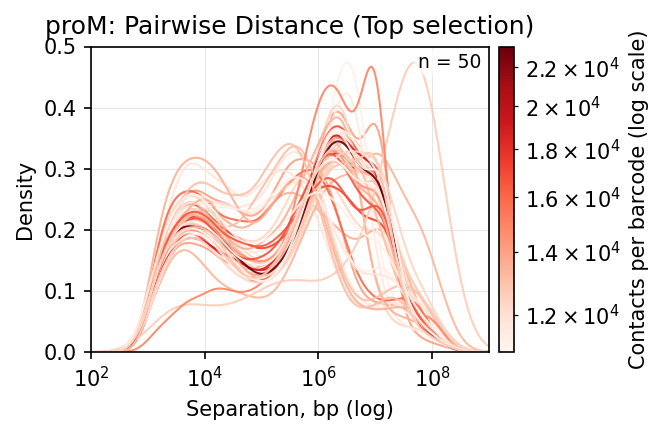

✅ Saved KDE to: /home/xiangru.huo-umw/scHiC/scripts/plot/proM_top50_kde.pdf


In [6]:
# proM (Reds) #need to manually remove the bad cells
plot_distance_kde_with_colorbar_pandas(
    df=df_proM_filter,
    selected_barcodes=top50_proM,
    contacts_map=contacts_proM,
    stage_name="proM",
    out_path="/home/xiangru.huo-umw/scHiC/scripts/plot/proM_top50_kde.pdf",
    cmap_name="Reds"
)

/tmp/ipykernel_2428056/1935518618.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap(cmap_name)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is de

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprec

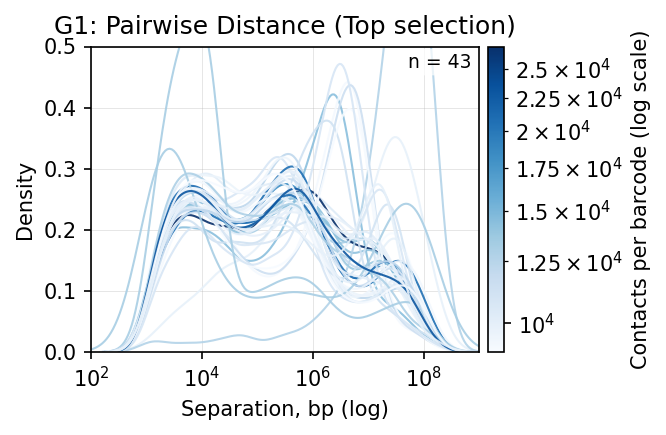

✅ Saved KDE to: /home/xiangru.huo-umw/scHiC/scripts/plot/G1_top50_kde.pdf


In [7]:
# G1 (Blues) #need to manually remove the bad cells
plot_distance_kde_with_colorbar_pandas(
    df=df_G1_filter,
    selected_barcodes=top50_G1,
    contacts_map=contacts_G1,
    stage_name="G1",
    out_path="/home/xiangru.huo-umw/scHiC/scripts/plot/G1_top50_kde.pdf",
    cmap_name="Blues"
)

# select the good cells using mitosis_band VS short_distance_band

In [8]:
# === Check load results ===
print("✅ proM pairs loaded:", df_proM_filter.shape)
print("✅ G1 pairs loaded:", df_G1_filter.shape)

print(df_proM_filter.head())

✅ proM pairs loaded: (16268216, 12)
✅ G1 pairs loaded: (17852974, 12)
                                              readID chrom1       pos1 chrom2  \
0  VH01361:133:2225TH7NX:1:2416:63731:3984:rAAAAA...   chr2   32916274   chr2   
1  VH01361:133:2225TH7NX:1:2416:64898:21891:rAAAA...  chr21   15330888  chr21   
2  VH01361:133:2225TH7NX:1:2416:61193:9919:rAAAAA...   chr5   67842273  chr20   
3  VH01361:133:2225TH7NX:1:2416:56786:3350:rAAAAA...   chr7   18371696   chr7   
4  VH01361:133:2225TH7NX:1:2416:56769:3333:rAAAAA...   chr7  125702330  chr11   

        pos2 strand1 strand2 pair_type  mapq1  mapq2               BX1  \
0  146909069       -       +        UU     49     60  AAAAAAAAAAAAAAAA   
1   15331326       +       -        UU     60     60  AAAAAAAAAAAAAAAA   
2    5778957       +       +        UU     60     60  AAAAAAAAAAAAAAAA   
3  118703813       -       -        UU     60      1  AAAAAAAAAAAAAAAA   
4   17889597       -       -        UU      4     60  AAAAAAAAAAAAAAAA   

In [9]:
def count_barcodes(df, stage_name, min_contacts=5000):
    """
    Count contacts per BX1 barcode and filter those with > min_contacts.
    Prints summary and returns filtered dataframe.
    """
    # Step 1. Count contacts per BX1
    counts = df["BX1"].value_counts().rename("cnt").reset_index().rename(columns={"index": "BX1"})

    # Step 2. Merge counts back
    df_with_counts = df.merge(counts, on="BX1", how="left")

    # Step 3. Filter for BX1 with > threshold
    filtered_df = df_with_counts[df_with_counts["cnt"] > min_contacts]

    # Step 4. Count unique BX1
    n_bx1 = filtered_df["BX1"].nunique()
    print(f"{stage_name}: {n_bx1} BX1 barcodes with >{min_contacts:,} contacts")

    return filtered_df, n_bx1


# === Run for both datasets ===
filtered_proM, n_proM = count_barcodes(df_proM_filter, "proM", min_contacts=5000)
filtered_G1,   n_G1   = count_barcodes(df_G1_filter,   "G1",   min_contacts=5000)

proM: 1082 BX1 barcodes with >5,000 contacts
G1: 316 BX1 barcodes with >5,000 contacts


In [12]:
def build_short_vs_mitotic(df: pd.DataFrame, hg38_arms: pd.DataFrame, stage_name: str):
    """
    df: pandas DataFrame with columns:
        ['chrom1','pos1','chrom2','pos2','BX1', ...]
    hg38_arms: pandas DataFrame with a 'chrom' column listing chromosomes to keep
    """
    # 0) Remove bad or invalid BX1 barcodes
    bad_barcodes = {"", "0", "null", "GGGGGGGGGGGGGGGG"}
    df = df[~df["BX1"].isin(bad_barcodes)].copy()

    # 1) cis only, keep canonical chroms, compute |pos1-pos2|
    keep_chroms = set(hg38_arms["chrom"].tolist())
    cis = df[(df["chrom1"] == df["chrom2"]) & (df["chrom1"].isin(keep_chroms))].copy()

    # ensure numeric positions
    cis["pos1"] = pd.to_numeric(cis["pos1"], errors="coerce")
    cis["pos2"] = pd.to_numeric(cis["pos2"], errors="coerce")
    cis = cis.dropna(subset=["pos1", "pos2"])
    cis["Abs_Dist"] = (cis["pos1"] - cis["pos2"]).abs()

    # 2) masks
    total_mask   = cis["Abs_Dist"] > 1_500
    short_mask   = (cis["Abs_Dist"] >= 1_500)    & (cis["Abs_Dist"] <= 2_000_000)
    mitotic_mask = (cis["Abs_Dist"] >= 2_000_000) & (cis["Abs_Dist"] <= 12_000_000)

    # 3) counts per BX1
    total_counts   = cis.loc[total_mask].groupby("BX1").size().rename("total")
    short_counts   = cis.loc[short_mask].groupby("BX1").size().rename("short")
    mitotic_counts = cis.loc[mitotic_mask].groupby("BX1").size().rename("mitotic")

    # 4) align & fill
    counts = pd.concat([total_counts, short_counts, mitotic_counts], axis=1).fillna(0)

    # 5) ratios (epsilon to avoid /0)
    eps = 1e-3
    counts["Short_ratio(1.5K-2Mb)"]   = counts["short"]   / (counts["total"] + eps)
    counts["Mitotic_ratio(2Mb-12Mb)"] = counts["mitotic"] / (counts["total"] + eps)

    # 6) total cis contacts regardless of distance (within kept chroms)
    num_contacts = cis.groupby("BX1").size().rename("Num_Contacts")

    # 7) final table
    out = (
        counts.join(num_contacts, how="outer")
              .fillna(0)
              .reset_index()
              .rename(columns={"BX1": "barcodes"})
              [["barcodes", "Short_ratio(1.5K-2Mb)", "Mitotic_ratio(2Mb-12Mb)", "Num_Contacts"]]
    )

    # sort by Num_Contacts desc
    out = out.sort_values("Num_Contacts", ascending=False).reset_index(drop=True)

    print(f"{stage_name}: built ShortVSMitotic table with {len(out):,} barcodes (bad barcodes removed)")
    return out


# ---- Run for both dataframes ----
ShortVSMitotic_proM = build_short_vs_mitotic(df_proM_filter, hg38_arms, "proM")
ShortVSMitotic_G1   = build_short_vs_mitotic(df_G1_filter,   hg38_arms, "G1")

proM: built ShortVSMitotic table with 245,372 barcodes (bad barcodes removed)
G1: built ShortVSMitotic table with 220,609 barcodes (bad barcodes removed)


In [13]:
ShortVSMitotic_G1[ShortVSMitotic_G1['Num_Contacts'] > 8000]

,barcodes,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts
0,AGCCAATTGAGGTGAC,0.730403,0.145004,24325
1,TGCCGTGGATCGCTAA,0.763107,0.123735,19825
2,CTGCACGGACCCGAGT,0.770044,0.099733,17781
3,AAAGGGAGAGAAACAT,0.766559,0.099678,15781
4,AAGAACCCTCCTAGCG,0.734123,0.147195,12591
5,AGGAGGTTGCGACACC,0.744026,0.136133,12063
6,AGATACGCTTCTATCT,0.683720,0.251099,11808
7,CGACCTACTTCATTTC,0.754792,0.110807,11766
8,CATTCAACTCCGGACT,0.761808,0.088814,11206
9,ACACAGACTTAATGCC,0.731568,0.142797,10986


In [82]:
import plotly.express as px
import plotly.graph_objects as go

def plot_short_vs_mitotic(df, stage_name, color, out_path):
    """
    Plot Short vs Mitotic ratios per cell for one stage.
    df          : pandas DataFrame with ratio columns
    stage_name  : label (e.g., "proM" or "G1")
    color       : marker color
    out_path    : output PDF file path
    """
    # --- Filter by number of contacts ---
    df_plot = df[df["Num_Contacts"] > 5_000].copy()

    # --- Build figure ---
    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=df_plot["Mitotic_ratio(2Mb-12Mb)"],
        y=df_plot["Short_ratio(1.5K-2Mb)"],
        mode="markers",
        marker=dict(size=5, color=color, opacity=0.8),
        name=stage_name
    ))

    # --- Layout ---
    fig.update_layout(
        title=f"{stage_name}: Short vs Mitotic Contact Ratios per Cell (>5K contacts after filter)",
        autosize=False,
        width=500,
        height=500,
        margin=dict(l=30, r=30, t=30, b=20),
        plot_bgcolor='rgba(0,0,0,0)',
        paper_bgcolor='rgba(0,0,0,0)',
        showlegend=False
    )

    # --- Add rectangles (same across both plots) ---
    fig.update_layout(
        shapes=[
            dict(type='rect', xref='x', yref='y',
                 x0=0, y0=0, x1=0.4, y1=1,
                 line=dict(color='black', width=1)),
            dict(type='rect', xref='x', yref='y',
                 x0=0.02, y0=0.7, x1=0.15, y1=0.9,
                 line=dict(color='blue', width=1)),
            dict(type='rect', xref='x', yref='y',
                 x0=0.25, y0=0.5, x1=0.38, y1=0.68,
                 line=dict(color='red', width=1))
        ]
    )

    # --- Save PDF ---
    fig.write_image(out_path, width=450, height=400, scale=2, format='pdf')
    print(f"✅ Saved: {out_path}")

    fig.show()


# === Run for both stages ===
plot_short_vs_mitotic(
    ShortVSMitotic_proM,
    stage_name="proM",
    color="red",
    out_path="/home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiC_proM_Short_vs_Mitotic_ratio_per_cell_gt20K.pdf"
)

plot_short_vs_mitotic(
    ShortVSMitotic_G1,
    stage_name="G1",
    color="blue",
    out_path="/home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiC_G1_Short_vs_Mitotic_ratio_per_cell_gt20K.pdf"
)

✅ Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiC_proM_Short_vs_Mitotic_ratio_per_cell_gt20K.pdf


✅ Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiC_G1_Short_vs_Mitotic_ratio_per_cell_gt20K.pdf


In [83]:
#label the phase
# === Define box boundaries ===
XCOL = "Mitotic_ratio(2Mb-12Mb)"
YCOL = "Short_ratio(1.5K-2Mb)"
BLUE_X, BLUE_Y = (0.02, 0.15), (0.70, 0.90)   # G1 region
RED_X,  RED_Y  = (0.25, 0.38), (0.5, 0.68)   # proM region

SAVE_DIR = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"
os.makedirs(SAVE_DIR, exist_ok=True)

def label_and_save(df, name):
    """Filter contacts >1000, label box phase, save to CSV."""
    df_filt = df[df["Num_Contacts"] > 1000].copy()
    x, y = df_filt[XCOL], df_filt[YCOL]

    in_blue = x.between(*BLUE_X, inclusive="both") & y.between(*BLUE_Y, inclusive="both")
    in_red  = x.between(*RED_X,  inclusive="both") & y.between(*RED_Y,  inclusive="both")

    df_filt["phase"] = np.where(in_blue, "G1",
                         np.where(in_red,  "proM", "undetermined"))

    out_path = os.path.join(SAVE_DIR, f"{name}_labeled.csv")
    df_filt.to_csv(out_path, index=False)
    print(f"✅ Saved {name} labeled table → {out_path}")
    print(df_filt["phase"].value_counts().to_dict())
    return df_filt

# === Apply to both datasets ===
ShortVSMitotic_G1_labeled  = label_and_save(ShortVSMitotic_G1,  "ShortVSMitotic_G1")
ShortVSMitotic_proM_labeled = label_and_save(ShortVSMitotic_proM, "ShortVSMitotic_proM")

✅ Saved ShortVSMitotic_G1 labeled table → /home/xiangru.huo-umw/scHiC/scripts/inter_file/ShortVSMitotic_G1_labeled.csv
{'G1': 2002, 'undetermined': 419, 'proM': 76}
✅ Saved ShortVSMitotic_proM labeled table → /home/xiangru.huo-umw/scHiC/scripts/inter_file/ShortVSMitotic_proM_labeled.csv
{'proM': 1104, 'undetermined': 544, 'G1': 507}


In [84]:
ShortVSMitotic_G1_labeled 

,barcodes,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,phase
0,AGCCAATTGAGGTGAC,0.730403,0.145004,24325,G1
1,TGCCGTGGATCGCTAA,0.763107,0.123735,19825,G1
2,CTGCACGGACCCGAGT,0.770044,0.099733,17781,G1
3,AAAGGGAGAGAAACAT,0.766559,0.099678,15781,G1
4,AAGAACCCTCCTAGCG,0.734123,0.147195,12591,G1
...,...,...,...,...,...
2492,GGACACCTGGCTTACA,0.834730,0.070659,1003,G1
2493,ATCCTCGACTTGTACG,0.791261,0.090615,1003,G1
2494,CTAACAGTGGCGTATT,0.729474,0.083445,1002,G1
2495,AAGGCTTACTGCGTGC,0.750711,0.096866,1002,G1


In [85]:
ShortVSMitotic_proM_labeled

,barcodes,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,phase
0,TCGCCTCCTTGCGCCA,0.625054,0.255404,19475,proM
1,GCCGACAACTTACGCA,0.623936,0.267499,16214,proM
2,CATTAGTCTGAACATA,0.635238,0.245586,15412,undetermined
3,CGTTACCTGCTCGAGC,0.693938,0.187023,14074,undetermined
4,TCCGAATGATGGCTGC,0.672155,0.213783,13954,undetermined
...,...,...,...,...,...
2150,TTGACAGTGCGGTTGC,0.667449,0.220916,1017,undetermined
2151,TCGACTCACAGTAGGC,0.599050,0.232503,1015,undetermined
2152,GCGAAGCCTAAAGCTA,0.581364,0.275590,1006,proM
2153,TATCATGCTCAAGGTG,0.808916,0.075159,1004,G1


# calculate the cis/total tables

In [62]:
#get compartment files
compartment = pd.read_csv("/home/xiangru.huo-umw/scHiC/benchmark/plot_files/cooler_data/G1_merge.250kb.2combo.mapq30.byarm.eigs.cis.vecs.E1.bedGraph",
        sep="\t",
        header=None,
        comment="#",index_col=None)
compartment.columns = ['chrom', 'start', 'end', 'E1']

In [21]:
chrom_size = {
    'chr1': '248956422',    'chr2': '242193529',
    'chr3': '198295559',    'chr4': '190214555',
    'chr5': '181538259',    'chr6': '170805979',
    'chr7': '159345973',    'chr8': '145138636',
    'chr9': '138394717',    'chr10': '133797422',
    'chr11': '135086622',    'chr12': '133275309',
    'chr13': '114364328',    'chr14': '107043718',
    'chr15': '101991189',    'chr16': '90338345',
    'chr17': '83257441',    'chr18': '80373285',
    'chr19': '58617616',    'chr20': '64444167',
    'chr21': '46709983',    'chr22': '50818468',
    'chrX': '156040895',    'chrY': '57227415'}

chrom_size_df = pd.DataFrame(list(chrom_size.items()), columns=['chrom', 'Size'])
# Convert the 'Size' column to integer type
chrom_size_df['Size'] = chrom_size_df ['Size'].astype(int)

In [22]:
#identify unique_chrom_value
unique_chrom = compartment['chrom'].unique()
#remove chrM from unique_chrom
unique_chrom_nuclei = unique_chrom[:-1]

In [23]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [24]:
#apply "split_df_by_chrom" function 
comp_split = split_df_by_chrom(compartment)

In [25]:
#define a bin combine function (1M = 4, 2M = 8)
def create_continuous_ranges(df, Mg):
    original_list = df.index 
    # Split the indices into lists of length Mg
    index_lists = [original_list[i:i+Mg] for i in range(0, len(original_list), Mg)]

    df_Mg = pd.DataFrame(columns=["chrom", "start", "end", "E1"])
    
    # Loop through the index_lists
    for indices in index_lists:
        start_index = indices[0]
        end_index = indices[-1]       
        # Create a temporary DataFrame for the current continuous range
        df_continues_tmp = pd.DataFrame({
            "chrom": [df['chrom'][start_index]],
            "start": [df['start'][start_index]],
            "end": [df['end'][end_index]],
            "E1": [df['E1'][start_index:end_index].mean()]
        })        
        # Concatenate the temporary DataFrame to the main DataFrame
        df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
        df_Mg['start'] = df_Mg['start'].astype(int)
        df_Mg['end'] = df_Mg['end'].astype(int)
        df_Mg['E1'] = df_Mg['E1'].astype(float)
    
    # Add a Bin_ID column to the DataFrame
    df_Mg["Bin_ID"] = df_Mg["chrom"] + "_Bin" + df_Mg.index.astype(str)
    
    return df_Mg

In [26]:
#apply "create_continuous_ranges" function on comp_split
comp_chrom_bin = {}
for chrom in unique_chrom_nuclei:
    comp_chrom_bin[chrom] = create_continuous_ranges(comp_split[chrom], 4)

/tmp/ipykernel_2428056/2299579928.py:21: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

/tmp/ipykernel_2428056/2299579928.py:21: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

/tmp/ipykernel_2428056/2299579928.py:21: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat o

In [27]:
#get comp bin table
comp_bin = pd.concat(comp_chrom_bin.values(), ignore_index=True)

In [28]:
bf.is_bedframe(comp_bin)

True

In [125]:
# Cells in proM phase with >5000 contacts
proM_barcode = ShortVSMitotic_proM_labeled[
    (ShortVSMitotic_proM_labeled['phase'] == 'proM') &
    (ShortVSMitotic_proM_labeled['Num_Contacts'] > 5000)
]['barcodes']


# Cells specifically in G1 phase with >5000 contacts
G1_barcode = ShortVSMitotic_G1_labeled[
    (ShortVSMitotic_G1_labeled['phase'] == 'G1') &
    (ShortVSMitotic_G1_labeled['Num_Contacts'] > 5000)
]['barcodes']

In [87]:
def generate_contacts_bin_id(df, comp_bin):
    """
    Assigns bin IDs to each contact using comp_bin (pandas-only version).

    Parameters
    ----------
    df : pandas.DataFrame
        Must contain ['chrom1','pos1','chrom2','pos2','BX1']
    comp_bin : pandas.DataFrame
        Must contain ['chrom','start','end','Bin_ID'] (e.g. from bioframe.make_bins)

    Returns
    -------
    pandas.DataFrame with:
        ['chrom1','pos1','Bin_ID_1','chrom2','pos2','Bin_ID_2','barcodes']
    """

    # --- Part A: assign bins to pos1 ---
    df1 = df[["chrom1", "pos1"]].copy()
    df1["end"] = df1["pos1"] + 1
    df1 = df1.rename(columns={"chrom1": "chrom", "pos1": "start"})
    df1_bin = bf.overlap(df1, comp_bin, how="left", suffixes=("_q", "_b"))
    df1_bin = df1_bin[["chrom_q", "start_q", "Bin_ID_b"]]
    df1_bin.columns = ["chrom1", "pos1", "Bin_ID_1"]

    # --- Part B: assign bins to pos2 ---
    df2 = df[["chrom2", "pos2", "BX1"]].copy()
    df2["end"] = df2["pos2"] + 1
    df2 = df2.rename(columns={"chrom2": "chrom", "pos2": "start", "BX1": "barcodes"})
    df2_bin = bf.overlap(df2, comp_bin, how="left", suffixes=("_q", "_b"))
    df2_bin = df2_bin[["chrom_q", "start_q", "Bin_ID_b", "barcodes_q"]]
    df2_bin.columns = ["chrom2", "pos2", "Bin_ID_2", "barcodes"]

    # --- Combine results ---
    df_out = pd.concat([df1_bin.reset_index(drop=True), df2_bin.reset_index(drop=True)], axis=1)
    return df_out

In [37]:
def process_stage_contacts(df_with_counts, selected_barcodes, comp_bin, stage_label):
    """
    Clean, filter, assign genomic bins, and compute cis ratios per barcode.

    Parameters
    ----------
    df_with_counts : pandas.DataFrame
        Contact table containing ['chrom1','pos1','chrom2','pos2','BX1'].
    selected_barcodes : list or pandas.Index
        Barcodes (cells) to include.
    comp_bin : pandas.DataFrame
        Bin definitions with ['chrom','start','end','Bin_ID'].
    stage_label : str
        Label for the stage (e.g., 'proM', 'Asyn', 'G1').

    Returns
    -------
    dict
        Dictionary of {barcode: cis_ratio_dataframe}
    """

    print(f"\n=== Processing stage: {stage_label} ===")

    # --- Step 1: Clean up barcode strings ---
    df_with_counts = df_with_counts.copy()
    df_with_counts["BX1"] = df_with_counts["BX1"].astype(str).str.strip('" ').str.strip()
    df_with_counts = df_with_counts[df_with_counts["BX1"] != "BX1"]

    # --- Step 2: Filter for selected barcodes ---
    overlap = df_with_counts["BX1"].isin(selected_barcodes).sum()
    print(f"Overlap barcodes: {overlap} / {len(selected_barcodes)}")

    df_sel = df_with_counts[df_with_counts["BX1"].isin(selected_barcodes)].copy()
    print(f"✅ Filtered contacts: {len(df_sel):,}")

    if df_sel.empty:
        print(f"⚠️ No contacts found for {stage_label}. Skipping.")
        return {}

    # --- Step 3: Assign genomic bins ---
    df_bin = generate_contacts_bin_id(df_sel, comp_bin)
    print(f"✅ Assigned genomic bins: {len(df_bin):,} rows")

    # --- Step 4: Compute cis ratios per barcode ---
    stage_cis_ratio_Bin_ID = {}
    for bc, group in df_bin.groupby("barcodes"):
        result = calculate_cis_ratio(group.copy())
        stage_cis_ratio_Bin_ID[bc] = result

    print(f"✅ Computed cis ratios for {len(stage_cis_ratio_Bin_ID)} barcodes")

    return stage_cis_ratio_Bin_ID

In [38]:
#define the function to get the cis_ratio per cell + count of inter-chromsomes 
def calculate_cis_ratio(df: pd.DataFrame) -> pd.DataFrame:
    # pos1 view: Bin_ID_1 vs chrom2
    vc1 = (df.groupby(["Bin_ID_1","chrom2"], dropna=False)
             .size().reset_index(name="count"))
    cis_count1   = vc1.groupby("Bin_ID_1", as_index=False)["count"].max().rename(columns={"count":"cis_count1"})
    total_count1 = vc1.groupby("Bin_ID_1", as_index=False)["count"].sum().rename(columns={"count":"total_count1"})
    cis_ratio = pd.merge(cis_count1, total_count1, on="Bin_ID_1", how="outer")
    cis_ratio["trans_count1"] = cis_ratio["total_count1"] - cis_ratio["cis_count1"]

    # pos2 view: Bin_ID_2 vs chrom1  (rename to Bin_ID_1)
    vc2 = (df.groupby(["Bin_ID_2","chrom1"], dropna=False)
             .size().reset_index(name="count"))
    cis_count2   = vc2.groupby("Bin_ID_2", as_index=False)["count"].max().rename(columns={"count":"cis_count2"})
    total_count2 = vc2.groupby("Bin_ID_2", as_index=False)["count"].sum().rename(columns={"count":"total_count2"})
    cis_ratio2 = pd.merge(cis_count2, total_count2, on="Bin_ID_2", how="outer").rename(columns={"Bin_ID_2":"Bin_ID_1"})
    cis_ratio2["trans_count2"] = cis_ratio2["total_count2"] - cis_ratio2["cis_count2"]

    # optional metadata from pos2
    unique_chrom1 = df.groupby("Bin_ID_2", as_index=False)["chrom1"].nunique() \
                      .rename(columns={"Bin_ID_2":"Bin_ID_1", "chrom1":"Chromosome_counts"})

    # combine and finalize
    out = pd.merge(cis_ratio,  cis_ratio2,   on="Bin_ID_1", how="outer")
    out = pd.merge(out,         unique_chrom1, on="Bin_ID_1", how="left")

    out["cis_count_final"]   = out[["cis_count1","cis_count2"]].max(axis=1, skipna=True)
    out["trans_count_final"] = out["trans_count1"].fillna(0) + out["trans_count2"].fillna(0)
    out["total_count_final"] = out["cis_count_final"].fillna(0) + out["trans_count_final"].fillna(0)
    out["cis_ratio_final"]   = out["cis_count_final"] / out["total_count_final"].replace(0, pd.NA)
    return out

In [39]:
def process_barcode_group(df_filter, barcodes, comp_bin, label):
    """
    Filter contacts to barcodes, assign bins, and compute cis-ratio tables
    PER BARCODE. Returns:
      df_binID                : per-contact table with Bin_ID_1/2 + barcodes
      cisratio_dict (dict)    : {barcode -> cis-ratio DataFrame}
    Also saves df_binID and a stage-level quick union (for debugging).
    """
    if len(barcodes) == 0:
        print(f"[{label}] ⚠️ No barcodes provided, skipping.")
        return None, {}

    print(f"[{label}] Processing {len(barcodes)} barcodes...")
    df_sub = df_filter[df_filter["BX1"].isin(barcodes)].copy()
    print(f"[{label}] {len(df_sub):,} contacts retained after barcode filtering")

    # Assign bin IDs (your pandas version)
    df_binID = generate_contacts_bin_id(df_sub, comp_bin)

    # Compute a cis-ratio table PER barcode
    cisratio_dict = {bc: calculate_cis_ratio(g.copy())
                     for bc, g in df_binID.groupby("barcodes")}

    # Save raw per-contact + a quick stage union (optional)
    base = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/{label}_contacts_bins"
    df_binID.to_csv(f"{base}.txt", sep="\t", index=False)

    # quick union (not used for matrices; just for sanity check)
    union = pd.concat([df.assign(barcode=bc) for bc, df in cisratio_dict.items()],
                      ignore_index=True)
    union.to_csv(f"{base}_cisratio_union.txt", sep="\t", index=False)

    print(f"✅ [{label}] Saved:")
    print(f"   {base}.txt")
    print(f"   {base}_cisratio_union.txt")
    print(f"   per-barcode tables in memory: {len(cisratio_dict)}\n")

    return df_binID, cisratio_dict


def build_bin_matrix(cisratio_dict, selected_barcodes, comp_bin, value_col):
    """
    Build a barcode × Bin_ID matrix from PER-BARCODE cisratio tables.
    cisratio_dict: {barcode -> DataFrame with ['Bin_ID_1', value_col]}
    """
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin["Bin_ID"]})
    for bc in selected_barcodes:
        df = cisratio_dict.get(bc)
        if df is None or value_col not in df.columns:
            continue
        tmp = df[["Bin_ID_1", value_col]].copy()
        tmp.columns = ["Bin_ID_1", bc]
        df_sum = pd.merge(df_sum, tmp, how="outer", on="Bin_ID_1")
    df_sum = df_sum.sort_values("Bin_ID_1").set_index("Bin_ID_1")
    return df_sum.T

# get the folding variability score

In [34]:
def summarize_bin_level(cis_ratio_Bin_ID_sum, reads_Bin_ID_sum, comp_bin, stage):
    # Ensure columns are numeric Bin_ID and aligned
    cis_ratio_Bin_ID_sum = cis_ratio_Bin_ID_sum.copy()
    reads_Bin_ID_sum     = reads_Bin_ID_sum.copy()

    # Build summary frame indexed by Bin_ID
    df = comp_bin.copy()
    df = df.set_index("Bin_ID")

    # Per-bin stats across cells (columns = bins)
    df["cisratio_mean"] = cis_ratio_Bin_ID_sum.mean(axis=0)
    df["cisratio_S.D."] = cis_ratio_Bin_ID_sum.std(axis=0)
    # Avoid divide-by-zero: where mean==0 -> NaN CV
    df["cisratio_cv"] = df["cisratio_S.D."].where(df["cisratio_mean"] != 0) / df["cisratio_mean"].replace(0, pd.NA)

    # Total reads per bin across cells
    df["total_counts_Mean"] = reads_Bin_ID_sum.mean(axis=0)
    df["total_counts_sum"]  = reads_Bin_ID_sum.sum(axis=0)

    outpath = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_{stage}_comp_bin_cisratio_filter<0.4kb.txt"
    df.to_csv(outpath, sep="\t", index=True)
    print(f"✅ Saved: {outpath}")
    return df

In [126]:
# --- proM ---
outdir = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"

proM_binID, proM_dict = process_barcode_group(df_proM_filter, proM_barcode, comp_bin, "proM")
if proM_dict:  # dict: {barcode -> cisratio DataFrame}
    cis_ratio_Bin_ID_sum = build_bin_matrix(proM_dict, proM_barcode, comp_bin, "cis_ratio_final")
    cis_Bin_ID_sum       = build_bin_matrix(proM_dict, proM_barcode, comp_bin, "cis_count_final")
    reads_Bin_ID_sum     = build_bin_matrix(proM_dict, proM_barcode, comp_bin, "total_count_final")

    cis_ratio_Bin_ID_sum.to_csv(f"{outdir}/dropletHiC_cis_ratio_perBin_proM.txt", sep="\t")
    reads_Bin_ID_sum.to_csv(    f"{outdir}/dropletHiC_total_reads_perBin_proM.txt", sep="\t")
    cis_Bin_ID_sum.to_csv(      f"{outdir}/dropletHiC_total_cis_perBin_proM.txt", sep="\t")

    # Per-bin summary file
    summarize_bin_level(cis_ratio_Bin_ID_sum, reads_Bin_ID_sum, comp_bin, "proM")

[proM] Processing 333 barcodes...
[proM] 2,598,900 contacts retained after barcode filtering
✅ [proM] Saved:
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_contacts_bins.txt
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_contacts_bins_cisratio_union.txt
   per-barcode tables in memory: 333

✅ Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_proM_comp_bin_cisratio_filter<0.4kb.txt


In [114]:
# --- G1 ---
G1_binID, G1_dict = process_barcode_group(df_G1_filter, G1_barcode, comp_bin, "G1")
outdir = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"

if G1_dict:
    cis_ratio_Bin_ID_sum = build_bin_matrix(G1_dict, G1_barcode, comp_bin, "cis_ratio_final")
    cis_Bin_ID_sum       = build_bin_matrix(G1_dict, G1_barcode, comp_bin, "cis_count_final")
    reads_Bin_ID_sum     = build_bin_matrix(G1_dict, G1_barcode, comp_bin, "total_count_final")

    cis_ratio_Bin_ID_sum.to_csv(f"{outdir}/dropletHiC_cis_ratio_perBin_G1.txt", sep="\t")
    reads_Bin_ID_sum.to_csv(    f"{outdir}/dropletHiC_total_reads_perBin_G1.txt", sep="\t")
    cis_Bin_ID_sum.to_csv(      f"{outdir}/dropletHiC_total_cis_perBin_G1.txt", sep="\t")

    summarize_bin_level(cis_ratio_Bin_ID_sum, reads_Bin_ID_sum, comp_bin, "G1")

[G1] Processing 103 barcodes...
[G1] 938,998 contacts retained after barcode filtering
✅ [G1] Saved:
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/G1_contacts_bins.txt
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/G1_contacts_bins_cisratio_union.txt
   per-barcode tables in memory: 103

✅ Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_G1_comp_bin_cisratio_filter<0.4kb.txt


In [2]:
#load the cis_ratio_Bin_ID_sum
base = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"
droplet_proM = pd.read_csv(f"{base}/dropletHiC_proM_comp_bin_cisratio_filter<0.4kb.txt", sep="\t")
droplet_G1   = pd.read_csv(f"{base}/dropletHiC_G1_comp_bin_cisratio_filter<0.4kb.txt", sep="\t")

In [3]:
droplet_G1  

,Bin_ID,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
0,chr1_Bin0,chr1,0,1000000,NaN,0.819868,0.230233,0.280817,3.262295,199.0
1,chr1_Bin1,chr1,1000000,2000000,1.148394,0.777587,0.248587,0.319691,3.071429,258.0
2,chr1_Bin2,chr1,2000000,3000000,1.105662,0.865174,0.227816,0.263318,1.776119,119.0
3,chr1_Bin3,chr1,3000000,4000000,0.782916,0.789556,0.265384,0.336118,2.329545,205.0
4,chr1_Bin4,chr1,4000000,5000000,-1.075570,0.830073,0.228136,0.274839,2.400000,156.0
...,...,...,...,...,...,...,...,...,...,...
3097,chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
3098,chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
3099,chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0
3100,chrY_Bin56,chrY,56000000,57000000,NaN,0.983333,0.091287,0.092834,1.133333,34.0


/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


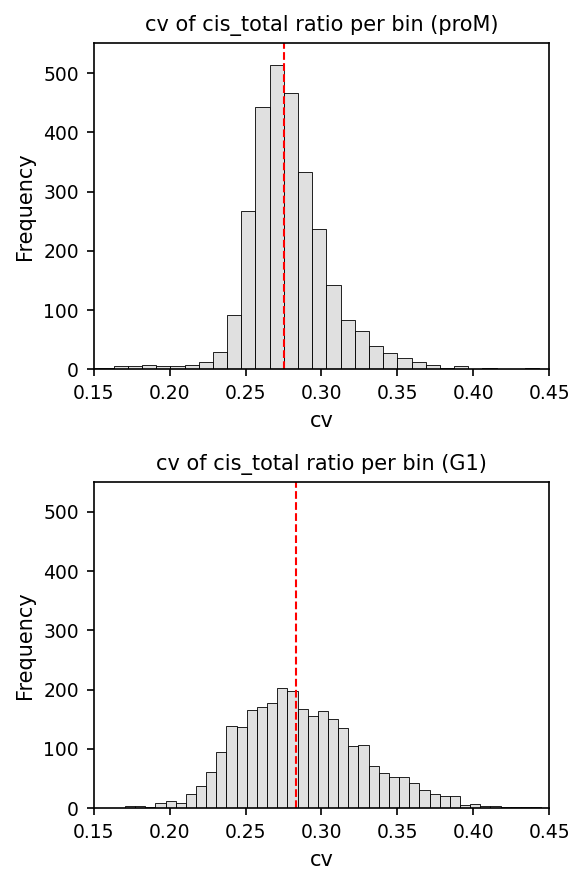

In [5]:
# Filter bins with sufficient total counts
droplet_proM = droplet_proM[droplet_proM["total_counts_sum"] >= 50]
droplet_G1   = droplet_G1[droplet_G1["total_counts_sum"] >= 50]

# Combine datasets for iteration
datasets = {
    "proM": droplet_proM,
    "G1": droplet_G1
}

# --- Plot: 3 rows, 1 column ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(4, 6), dpi=150)

for i, (stage, df) in enumerate(datasets.items()):
    median = df["cisratio_cv"].median()

    # Histogram
    sns.histplot(
        df["cisratio_cv"], bins=50, kde=False,
        color="lightgrey", alpha=0.7, ax=axes[i]
    )

    # Axis limits and style
    axes[i].set_xlim(0.15, 0.45)
    axes[i].set_ylim(0, 550)
    axes[i].axvline(x=median, color="red", linestyle="--", lw=1)

    axes[i].set_title(f"cv of cis_total ratio per bin ({stage})", fontsize=10)
    axes[i].set_xlabel("cv", fontsize=10)
    axes[i].set_ylabel("Frequency", fontsize=10)
    axes[i].tick_params(axis="both", which="major", labelsize=9)

plt.tight_layout()

# Save
#plt.savefig(
#    "/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_cv_perbin_proM_Asyn_G1.pdf",
#    format="pdf", bbox_inches="tight"
#)

plt.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


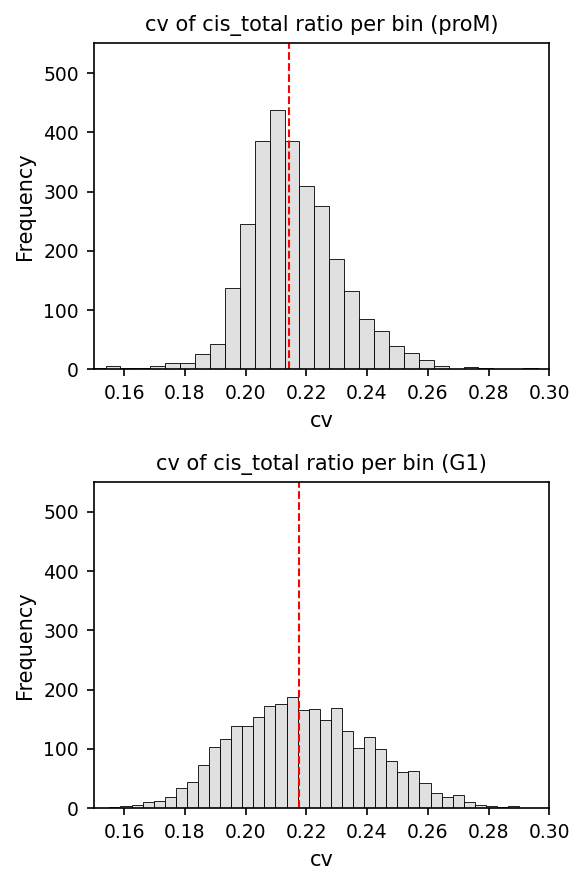

In [10]:
# Filter bins with sufficient total counts
droplet_proM = droplet_proM[droplet_proM["total_counts_sum"] >= 50]
droplet_G1   = droplet_G1[droplet_G1["total_counts_sum"] >= 50]

# Combine datasets for iteration
datasets = {
    "proM": droplet_proM,
    "G1": droplet_G1
}

# --- Plot: 3 rows, 1 column ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(4, 6), dpi=150)

for i, (stage, df) in enumerate(datasets.items()):
    median = df["cisratio_S.D."].median()

    # Histogram
    sns.histplot(
        df["cisratio_S.D."], bins=50, kde=False,
        color="lightgrey", alpha=0.7, ax=axes[i]
    )

    # Axis limits and style
    axes[i].set_xlim(0.15, 0.3)
    axes[i].set_ylim(0, 550)
    axes[i].axvline(x=median, color="red", linestyle="--", lw=1)

    axes[i].set_title(f"cv of cis_total ratio per bin ({stage})", fontsize=10)
    axes[i].set_xlabel("cv", fontsize=10)
    axes[i].set_ylabel("Frequency", fontsize=10)
    axes[i].tick_params(axis="both", which="major", labelsize=9)

plt.tight_layout()

# Save
plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_sd_perbin_proM_Asyn_G1.pdf",
    format="pdf", bbox_inches="tight")

plt.show()

In [ ]:
# get the folding variability score (downsampling to 100 barcodes, not change results)

In [134]:
def summarize_bin_level(cis_ratio_Bin_ID_sum, reads_Bin_ID_sum, comp_bin, stage, n_cells=100, random_state=42):
    """
    Compute per-bin summary statistics (mean, SD, CV, read totals),
    optionally downsampling to a subset of barcodes.

    Parameters
    ----------
    cis_ratio_Bin_ID_sum : pd.DataFrame
        rows = barcodes, columns = Bin_ID
    reads_Bin_ID_sum : pd.DataFrame
        rows = barcodes, columns = Bin_ID
    comp_bin : pd.DataFrame
        must contain 'Bin_ID'
    stage : str
        label for output filename
    n_cells : int, optional
        number of barcodes (rows) to randomly sample before summary
    random_state : int
        random seed for reproducibility
    """

    # --- Random downsampling of barcodes (rows) ---
    if len(cis_ratio_Bin_ID_sum) > n_cells:
        sampled_idx = np.random.choice(cis_ratio_Bin_ID_sum.index, n_cells, replace=False)
        cis_ratio_Bin_ID_sum = cis_ratio_Bin_ID_sum.loc[sampled_idx]
        reads_Bin_ID_sum = reads_Bin_ID_sum.loc[sampled_idx]
        print(f"🔹 Downsampled from {len(cis_ratio_Bin_ID_sum)} to {n_cells} barcodes.")

    # --- Build base comp_bin frame ---
    df = comp_bin.copy().set_index("Bin_ID")

    # --- Compute per-bin stats across sampled barcodes ---
    df["cisratio_mean"] = cis_ratio_Bin_ID_sum.mean(axis=0)
    df["cisratio_S.D."] = cis_ratio_Bin_ID_sum.std(axis=0)
    df["cisratio_cv"] = df["cisratio_S.D."].where(df["cisratio_mean"] != 0) / df["cisratio_mean"].replace(0, pd.NA)

    df["total_counts_Mean"] = reads_Bin_ID_sum.mean(axis=0)
    df["total_counts_sum"]  = reads_Bin_ID_sum.sum(axis=0)

    # --- Save ---
    outpath = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_{stage}_comp_bin_cisratio_filter<0.4kb_downsampled.txt"
    df.to_csv(outpath, sep="\t", index=True)
    print(f"✅ Saved (downsampled summary): {outpath}")

    return df

In [135]:
# --- proM ---
outdir = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"

proM_binID, proM_dict = process_barcode_group(df_proM_filter, proM_barcode, comp_bin, "proM")
if proM_dict:  # dict: {barcode -> cisratio DataFrame}
    # Build per-bin matrices (rows = barcodes, cols = Bin_ID)
    cis_ratio_Bin_ID_sum = build_bin_matrix(proM_dict, proM_barcode, comp_bin, "cis_ratio_final")
    cis_Bin_ID_sum       = build_bin_matrix(proM_dict, proM_barcode, comp_bin, "cis_count_final")
    reads_Bin_ID_sum     = build_bin_matrix(proM_dict, proM_barcode, comp_bin, "total_count_final")

    # Save full matrices
    cis_ratio_Bin_ID_sum.to_csv(f"{outdir}/dropletHiC_cis_ratio_perBin_proM.txt", sep="\t")
    reads_Bin_ID_sum.to_csv(    f"{outdir}/dropletHiC_total_reads_perBin_proM.txt", sep="\t")
    cis_Bin_ID_sum.to_csv(      f"{outdir}/dropletHiC_total_cis_perBin_proM.txt", sep="\t")

    # Per-bin summary with random downsampling to 100 barcodes (reproducible)
    summarize_bin_level(cis_ratio_Bin_ID_sum, reads_Bin_ID_sum, comp_bin,
                        stage="proM", n_cells=103, random_state=42)

[proM] Processing 333 barcodes...
[proM] 2,598,900 contacts retained after barcode filtering
✅ [proM] Saved:
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_contacts_bins.txt
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_contacts_bins_cisratio_union.txt
   per-barcode tables in memory: 333

🔹 Downsampled from 103 to 103 barcodes.
✅ Saved (downsampled summary): /home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_proM_comp_bin_cisratio_filter<0.4kb_downsampled.txt


In [136]:
# --- G1 ---
G1_binID, G1_dict = process_barcode_group(df_G1_filter, G1_barcode, comp_bin, "G1")
if G1_dict:  # dict: {barcode -> cisratio DataFrame}
    # Build per-bin matrices (rows = barcodes, cols = Bin_ID)
    cis_ratio_Bin_ID_sum = build_bin_matrix(G1_dict, G1_barcode, comp_bin, "cis_ratio_final")
    cis_Bin_ID_sum       = build_bin_matrix(G1_dict, G1_barcode, comp_bin, "cis_count_final")
    reads_Bin_ID_sum     = build_bin_matrix(G1_dict, G1_barcode, comp_bin, "total_count_final")

    # Save full matrices
    cis_ratio_Bin_ID_sum.to_csv(f"{outdir}/dropletHiC_cis_ratio_perBin_G1.txt", sep="\t")
    reads_Bin_ID_sum.to_csv(    f"{outdir}/dropletHiC_total_reads_perBin_G1.txt", sep="\t")
    cis_Bin_ID_sum.to_csv(      f"{outdir}/dropletHiC_total_cis_perBin_G1.txt", sep="\t")

    # Per-bin summary with random downsampling to 100 barcodes
    summarize_bin_level(cis_ratio_Bin_ID_sum, reads_Bin_ID_sum, comp_bin,
                        stage="G1", n_cells=103, random_state=42)

[Asyn] Processing 161 barcodes...
[Asyn] 1,398,607 contacts retained after barcode filtering
✅ [Asyn] Saved:
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/Asyn_contacts_bins.txt
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/Asyn_contacts_bins_cisratio_union.txt
   per-barcode tables in memory: 161

🔹 Downsampled from 103 to 103 barcodes.
✅ Saved (downsampled summary): /home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_Asyn_comp_bin_cisratio_filter<0.4kb_downsampled.txt
[G1] Processing 103 barcodes...
[G1] 938,998 contacts retained after barcode filtering
✅ [G1] Saved:
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/G1_contacts_bins.txt
   /home/xiangru.huo-umw/scHiC/scripts/inter_file/G1_contacts_bins_cisratio_union.txt
   per-barcode tables in memory: 103

✅ Saved (downsampled summary): /home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_G1_comp_bin_cisratio_filter<0.4kb_downsampled.txt


In [11]:
#load the cis_ratio_Bin_ID_sum
base = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"
droplet_proM_downsampling = pd.read_csv(f"{base}/dropletHiC_proM_comp_bin_cisratio_filter<0.4kb_downsampled.txt", sep="\t")
droplet_G1_downsampling   = pd.read_csv(f"{base}/dropletHiC_G1_comp_bin_cisratio_filter<0.4kb_downsampled.txt", sep="\t")

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



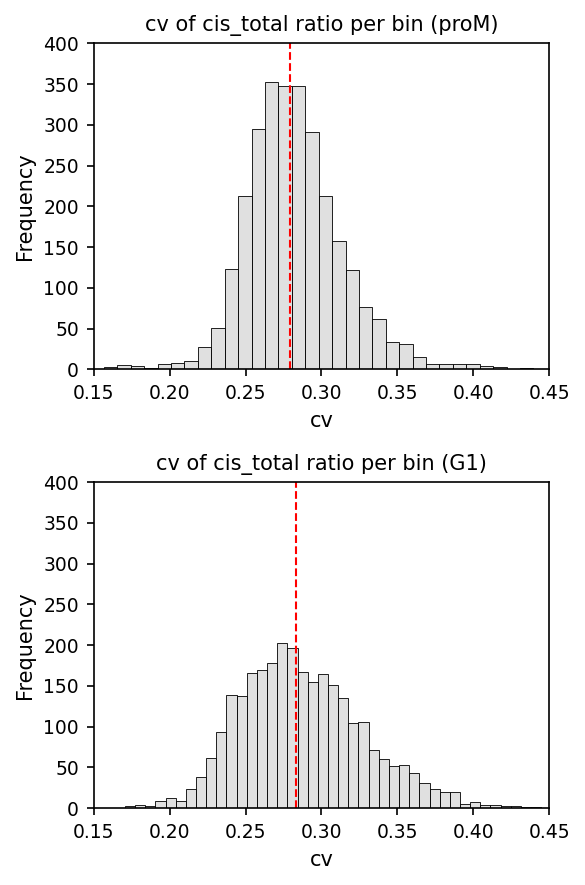

In [153]:
# Filter bins with sufficient total counts
droplet_proM_downsampling = droplet_proM_downsampling[droplet_proM_downsampling["total_counts_sum"] >= 50]
#droplet_Asyn_downsampling = droplet_Asyn_downsampling[droplet_Asyn_downsampling["total_counts_sum"] >= 10]
droplet_G1_downsampling   = droplet_G1_downsampling[droplet_G1_downsampling["total_counts_sum"] >= 50]

# Combine datasets for iteration
datasets = {
    "proM": droplet_proM_downsampling,
#    "Asyn": droplet_Asyn_downsampling,
    "G1": droplet_G1_downsampling
}

# --- Plot: 3 rows, 1 column ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(4, 6), dpi=150)

for i, (stage, df) in enumerate(datasets.items()):
    median = df["cisratio_cv"].median()

    # Histogram
    sns.histplot(
        df["cisratio_cv"], bins=50, kde=False,
        color="lightgrey", alpha=0.7, ax=axes[i]
    )

    # Axis limits and style
    axes[i].set_xlim(0.15, 0.45)
    axes[i].set_ylim(0, 400)
    axes[i].axvline(x=median, color="red", linestyle="--", lw=1)

    axes[i].set_title(f"cv of cis_total ratio per bin ({stage})", fontsize=10)
    axes[i].set_xlabel("cv", fontsize=10)
    axes[i].set_ylabel("Frequency", fontsize=10)
    axes[i].tick_params(axis="both", which="major", labelsize=9)

plt.tight_layout()

# Save
plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_cv_perbin_proM_Asyn_G1_downsampling.pdf",
    format="pdf", bbox_inches="tight"
)

plt.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


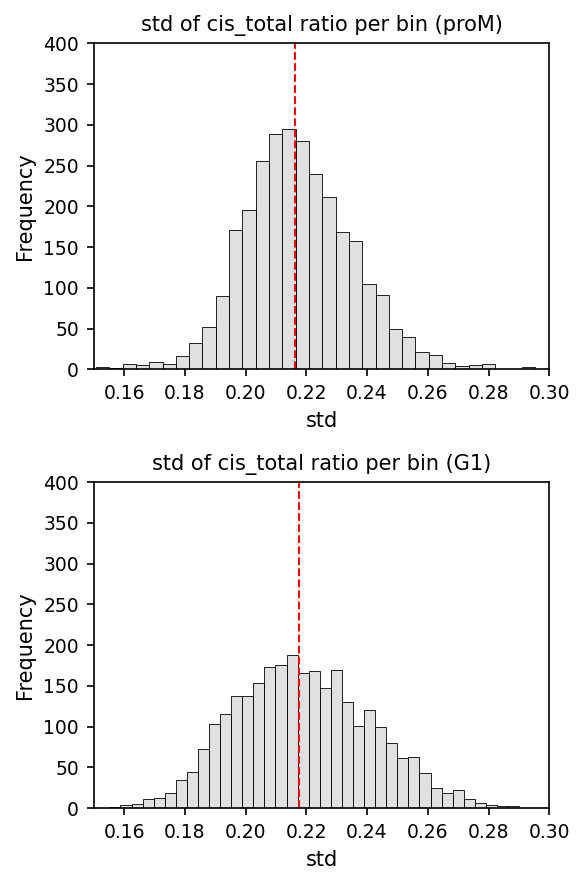

In [13]:
# Filter bins with sufficient total counts
droplet_proM_downsampling = droplet_proM_downsampling[droplet_proM_downsampling["total_counts_sum"] >= 50]
#droplet_Asyn_downsampling = droplet_Asyn_downsampling[droplet_Asyn_downsampling["total_counts_sum"] >= 10]
droplet_G1_downsampling   = droplet_G1_downsampling[droplet_G1_downsampling["total_counts_sum"] >= 50]

# Combine datasets for iteration
datasets = {
    "proM": droplet_proM_downsampling,
#    "Asyn": droplet_Asyn_downsampling,
    "G1": droplet_G1_downsampling
}

# --- Plot: 3 rows, 1 column ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(4, 6), dpi=150)

for i, (stage, df) in enumerate(datasets.items()):
    median = df["cisratio_S.D."].median()

    # Histogram
    sns.histplot(
        df["cisratio_S.D."], bins=50, kde=False,
        color="lightgrey", alpha=0.7, ax=axes[i]
    )

    # Axis limits and style
    axes[i].set_xlim(0.15, 0.3)
    axes[i].set_ylim(0, 400)
    axes[i].axvline(x=median, color="red", linestyle="--", lw=1)

    axes[i].set_title(f"std of cis_total ratio per bin ({stage})", fontsize=10)
    axes[i].set_xlabel("std", fontsize=10)
    axes[i].set_ylabel("Frequency", fontsize=10)
    axes[i].tick_params(axis="both", which="major", labelsize=9)

plt.tight_layout()

# Save
plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_std_perbin_proM_Asyn_G1_downsampling.pdf",
    format="pdf", bbox_inches="tight"
)

plt.show()

# compartment strength in Fig S1f

In [6]:
#get compartment files
compartment = pd.read_csv("/home/xiangru.huo-umw/scHiC/benchmark/plot_files/cooler_data/G1_merge.250kb.2combo.mapq30.byarm.eigs.cis.vecs.E1.bedGraph",
        sep="\t",
        header=None,
        comment="#",index_col=None)
print(len(compartment.dropna()))

11047


In [7]:
#compartment A/B separated into two parts
compartment_A = compartment[compartment[3]>0]
compartment_B =compartment[compartment[3]<0]
compartment_A = compartment_A.loc[:,[0,1,2]]
compartment_A.columns =['chrom', 'start', 'end']
compartment_A['comp'] = 'A'
compartment_B = compartment_B.loc[:,[0,1,2]]
compartment_B.columns =['chrom', 'start', 'end']
compartment_B['comp'] = 'B'
compartment_B [compartment_B ['chrom']  == 'chr1']

,chrom,start,end,comp
13,chr1,3250000,3500000,B
15,chr1,3750000,4000000,B
16,chr1,4000000,4250000,B
17,chr1,4250000,4500000,B
18,chr1,4500000,4750000,B
...,...,...,...,...
989,chr1,247250000,247500000,B
992,chr1,248000000,248250000,B
993,chr1,248250000,248500000,B
994,chr1,248500000,248750000,B


In [ ]:
# Get cells have fewest contacts > 10K
def count_barcodes(df, stage_name, min_contacts=6000):
    """
    Count contacts per BX1 barcode and filter those with > min_contacts.
    Prints summary and returns filtered dataframe.
    """
    # Step 1. Count contacts per BX1
    counts = df["BX1"].value_counts().rename("cnt").reset_index().rename(columns={"index": "BX1"})

    # Step 2. Merge counts back
    df_with_counts = df.merge(counts, on="BX1", how="left")

    # Step 3. Filter for BX1 with > threshold
    filtered_df = df_with_counts[df_with_counts["cnt"] > min_contacts]

    # Step 4. Count unique BX1
    n_bx1 = filtered_df["BX1"].nunique()
    print(f"{stage_name}: {n_bx1} BX1 barcodes with >{min_contacts:,} contacts")

    return filtered_df, n_bx1


# === Run for both datasets ===
filtered_proM, n_proM = count_barcodes(df_proM_filter, "proM", min_contacts=6000)
filtered_G1,   n_G1   = count_barcodes(df_G1_filter,   "G1",   min_contacts=6000)

In [ ]:
# calculate compartment strength
import bioframe as bf

def pairs_to_pos_beds(df_pairs, min_dist=250_000):
    """
    Input df_pairs must contain: chrom1, pos1, chrom2, pos2 (or chrom1,pos1,pos2 if cis only).
    Returns df_pos1, df_pos2 as 1-bp BEDs: chrom,start,end.
    """
    df = df_pairs.copy()

    # enforce cis
    if "chrom2" in df.columns:
        df = df[df["chrom1"] == df["chrom2"]].copy()

    # distance filter (pos2 - pos1 should be positive; if not, sort)
    # ensure pos1 <= pos2
    if "pos2" in df.columns:
        swap = df["pos1"] > df["pos2"]
        df.loc[swap, ["pos1", "pos2"]] = df.loc[swap, ["pos2", "pos1"]].values

    df["dis"] = df["pos2"] - df["pos1"]
    df = df[df["dis"] > min_dist].copy()

    # 1-bp BEDs
    df_pos1 = df.loc[:, ["chrom1", "pos1"]].copy()
    df_pos1["end"] = df_pos1["pos1"] + 1
    df_pos1 = df_pos1.rename(columns={"chrom1": "chrom", "pos1": "start"})[["chrom", "start", "end"]]

    df_pos2 = df.loc[:, ["chrom1", "pos2"]].copy()
    df_pos2["end"] = df_pos2["pos2"] + 1
    df_pos2 = df_pos2.rename(columns={"chrom1": "chrom", "pos2": "start"})[["chrom", "start", "end"]]

    return df_pos1, df_pos2, df  # also return filtered pairs for counts


def label_compartment(df_pos, compartment_A, compartment_B):
    """
    Given df_pos (chrom,start,end), return a Series with labels: 'A', 'B', 'None'
    Uses bf.overlap(..., how='left') and checks whether an overlap exists.
    """
    ovA = bf.overlap(df_pos, compartment_A, how="left", suffixes=("", "_A"))
    ovB = bf.overlap(df_pos, compartment_B, how="left", suffixes=("", "_B"))

    # If overlap exists, bioframe puts matched interval columns (chrom_A/start_A/end_A) not-null.
    # We detect overlap by presence of start_A/start_B.
    hasA = ovA.get("start_A", pd.Series([np.nan]*len(df_pos))).notna()
    hasB = ovB.get("start_B", pd.Series([np.nan]*len(df_pos))).notna()

    # priority: A if overlaps A; B if overlaps B; None otherwise
    # (If you have rare A/B overlaps due to boundaries, this chooses A; change if you prefer.)
    comp = np.where(hasA, "A", np.where(hasB, "B", "None"))
    return pd.Series(comp, index=df_pos.index, name="comp")


def compute_compartment_ratios(df_pairs_filtered, compartment_A, compartment_B):
    """
    df_pairs_filtered must contain chrom1,pos1,pos2 (and optionally chrom2).
    Returns:
      pos1_2 table with compartments for both ends
      summary dict with AA, BB, AB+BA, strength, N
    """
    df_pos1, df_pos2, df_filt = pairs_to_pos_beds(df_pairs_filtered, min_dist=min_dist)

    comp1 = label_compartment(df_pos1, compartment_A, compartment_B)
    comp2 = label_compartment(df_pos2, compartment_A, compartment_B)

    pos1_2 = pd.DataFrame({
        "chrom_1": df_pos1["chrom"],
        "start_1": df_pos1["start"],
        "end_1":   df_pos1["end"],
        "compartment_1": comp1,
        "chrom_2": df_pos2["chrom"],
        "start_2": df_pos2["start"],
        "end_2":   df_pos2["end"],
        "compartment_2": comp2
    }, index=df_pos1.index)

    N = len(pos1_2)
    if N == 0:
        return pos1_2, {"AA_real": np.nan, "BB_real": np.nan, "AB+BA_real": np.nan, "comp_strength": np.nan, "Num_Contacts": 0}

    AA = ((pos1_2["compartment_1"] == "A") & (pos1_2["compartment_2"] == "A")).sum() / N
    BB = ((pos1_2["compartment_1"] == "B") & (pos1_2["compartment_2"] == "B")).sum() / N
    AB = ((pos1_2["compartment_1"] == "A") & (pos1_2["compartment_2"] == "B")).sum() / N
    BA = ((pos1_2["compartment_1"] == "B") & (pos1_2["compartment_2"] == "A")).sum() / N

    denom = (AB + BA)
    strength = (AA + BB) / denom if denom > 0 else np.inf

    summary = {
        "AA_real": AA,
        "BB_real": BB,
        "AB+BA_real": AB + BA,
        "comp_strength": strength,
        "Num_Contacts": N
    }
    return pos1_2, summary

In [ ]:
#set binsize (compartment size)
min_dist = 250_000

In [ ]:
def per_cell_compartment_ratios(df_pairs, compartment_A, compartment_B, cell_col="BX1", min_dist=250_000):
    out = []
    for bx1, sub in df_pairs.groupby(cell_col, sort=False):
        needed = ["chrom1", "pos1", "pos2"]
        if "chrom2" in sub.columns:
            needed = ["chrom1", "pos1", "chrom2", "pos2"]
        pos1_2, summary = compute_compartment_ratios(sub.loc[:, needed], compartment_A, compartment_B)
        summary[cell_col] = bx1
        out.append(summary)
    return pd.DataFrame(out)

proM_cell_ratio = per_cell_compartment_ratios(filtered_proM, compartment_A, compartment_B, cell_col="BX1", min_dist=min_dist)
G1_cell_ratio   = per_cell_compartment_ratios(filtered_G1,   compartment_A, compartment_B, cell_col="BX1", min_dist=min_dist)

In [ ]:
#prepare to plot violinplots
Contact = 1000
TOPN = 200

df = Ratio_singlecell_total.copy()

# 1) remove BX1 == 0 (handles both int 0 and string "0")
if "BX1" in df.columns:
    df = df[~df["BX1"].isin([0, "0"])].copy()

# 2) ensure numeric columns
df["Num_Contacts"]  = pd.to_numeric(df["Num_Contacts"], errors="coerce")
df["comp_strength"] = pd.to_numeric(df["comp_strength"], errors="coerce")

# 3) filter by contacts threshold + valid comp_strength
df = df[(df["Num_Contacts"] > Contact) & (df["comp_strength"].notna())].copy()

# 4) keep top 200 cells per condition (by Num_Contacts)
df_top = (
    df.sort_values(["type", "Num_Contacts"], ascending=[True, False])
      .groupby("type", group_keys=False)
      .head(TOPN)
      .copy()
)

In [ ]:
#violin plots
import plotly.express as px
import plotly.graph_objects as go

fig = px.violin(
    df_top,
    x="type",
    y="comp_strength",
    color="type",
    box=True,
    points="all",
    title=f"Compartment strength per single cell (contacts > {Contact:,})"
)

fig.update_layout(
    autosize=False,
    width=300,
    height=500,
    margin=dict(l=40, r=40, t=40, b=40),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    title=dict(x=0.0),
    showlegend=False,
    shapes=[
        go.layout.Shape(
            type="rect",
            x0=0,
            x1=1,
            y0=0,
            y1=1,
            xref="paper",
            yref="paper",
            line=dict(color="black", width=1)
        )
    ]
)

fig.update_yaxes(range=[0.9, 1.6])

fig.write_image(
    f"/home/xiangru.huo-umw/scHiC/scripts/plot/Benchmark_scCompStrength_contacts_droplet>{Contact}.pdf",
    width=300,
    height=500,
    scale=2
)

fig.show()